# **Project Name**    - Restaurant Clustering 



##### **Project Type**    - Unsupervised
##### **Contribution**    - Individual 

# **Project Summary -**

This project presents an end-to-end analytical framework for restaurant segmentation using customer reviews, operational attributes, and business-related features. The primary objective was to understand patterns in restaurant performance, customer perception, and operational characteristics, and to group restaurants into meaningful segments that can support data-driven business decisions. The analysis combined structured data processing, natural language preprocessing, feature engineering, and unsupervised machine learning techniques to derive actionable insights.

The project began with extensive data wrangling and preprocessing. Review-level data was cleaned by handling missing values, removing noise, and performing text preprocessing steps such as lowercasing, punctuation removal, stopword removal, lemmatization, and vectorization using TF-IDF. This ensured that textual information from customer reviews could be effectively utilized for sentiment and feature extraction. Structured attributes such as cost, cuisine categories, service availability, and operational timings were standardized, encoded, and transformed into numerical representations suitable for machine learning models. Outliers were identified and treated using IQR-based capping and log transformations to reduce skewness while preserving important business information.

A key step in the pipeline was aggregation from review-level data to restaurant-level data. This prevented duplication bias caused by multiple reviews per restaurant and ensured that each restaurant was represented as a single entity with consolidated metrics such as average rating, popularity indicators, cuisine diversity, and operational characteristics. Feature manipulation and selection techniques were applied to reduce redundancy, create meaningful composite indicators (such as value-for-money and popularity scores), and retain only business-relevant attributes.

Three unsupervised machine learning models were implemented and evaluated: K-Means clustering, DBSCAN, and Hierarchical (Agglomerative) clustering. Model performance was assessed using internal validation metrics including Silhouette Score, Davies–Bouldin Index, and Inertia. These metrics measured how well restaurants were separated into distinct groups and how compact each group was. Among the three approaches, K-Means consistently achieved the highest Silhouette Score and the lowest Davies–Bouldin Index, indicating superior cluster separation and compactness. DBSCAN failed to identify meaningful density-based clusters for this dataset, while Hierarchical clustering formed fewer and less distinct clusters. Based on these results, K-Means was selected as the final model due to its stability, scalability, and business interpretability.

To enhance transparency and trust in the model, feature explainability was performed using centroid-based analysis. By examining the variance of features across cluster centroids, the most influential drivers of segmentation were identified. These included pricing (cost), customer ratings, popularity metrics, cuisine indicators, service availability, and operational timing features. Visualization of clusters using PCA further validated the separation of restaurant groups and provided intuitive insight into the structure of the data.

From a business perspective, the clustering solution delivers significant value. It enables targeted marketing and personalized recommendations by identifying distinct restaurant segments based on customer satisfaction, affordability, cuisine specialization, and operational style. Pricing strategies can be optimized by differentiating budget, mid-range, and premium clusters. Operational decisions such as extending service hours, introducing new cuisines, or improving underperforming segments can be guided by cluster-specific characteristics. Additionally, the model supports the identification of niche or outlier restaurants, allowing focused interventions for improvement or strategic repositioning.

In conclusion, this project demonstrates a robust and interpretable approach to restaurant analytics by integrating NLP-based review insights with structured business data and validated clustering techniques. The final K-Means model provides meaningful segmentation that aligns closely with real-world business objectives. By transforming raw data into actionable intelligence, the solution offers a scalable framework for enhancing customer experience, improving operational efficiency, and supporting strategic decision-making in the restaurant and hospitality domain.

# **GitHub Link -**

https://github.com/psa21git/Zomato_Restaurant_Clustering

# **Problem Statement**


The restaurant and hospitality industry generates large volumes of customer reviews and operational data across pricing, cuisine types, service availability, and customer engagement metrics. However, this data is often underutilized for strategic decision-making due to its unstructured nature and the lack of effective segmentation. Without meaningful grouping of restaurants based on business performance and customer perception, organizations struggle to implement targeted marketing, optimize pricing strategies, improve service quality, and enhance customer experience.

The objective of this project is to analyze and segment restaurants into meaningful clusters using both structured attributes (such as cost, ratings, cuisine categories, operational features, and popularity indicators) and unstructured customer review data. By applying data preprocessing, feature engineering, and unsupervised machine learning techniques, the project aims to identify natural groupings among restaurants that reflect similarities in business characteristics and customer behavior.

Specifically, this project seeks to address the following challenges:

- How can heterogeneous restaurant data, including textual reviews and numerical business attributes, be transformed into a clean and analyzable format?

- Which clustering technique provides the most effective segmentation in terms of cluster separation, compactness, and business interpretability?

- How can the resulting restaurant segments be interpreted to support real-world business decisions such as targeted marketing, pricing optimization, service improvements, and operational planning?

By solving these problems, the project aims to develop a scalable, interpretable, and data-driven segmentation framework that enables restaurant owners, aggregators, and analysts to better understand market structure, identify performance patterns, and design strategies tailored to different restaurant segments.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [288]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import time
# !pip install nltk
import nltk
from nltk.corpus import stopwords

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.metrics import silhouette_score

from sklearn.cluster import DBSCAN
from sklearn.cluster import AgglomerativeClustering

# !pip install gdown
import gdown

### Dataset Loading

In [289]:
url1 = "https://drive.google.com/uc?export=download&id=10EgQdICQOQ4zbmS2SLYuJHAgHex909dz"
url2 = "https://drive.google.com/uc?export=download&id=1Vzv_rMIO_LoG3KUalYFj5NrzD0MvI9ng"

df1 = pd.read_csv(url1)
df2 = pd.read_csv(url2)

In [290]:
# Load Dataset
# url1 = "https://drive.google.com/file/d/10EgQdICQOQ4zbmS2SLYuJHAgHex909dz/view?usp=drive_link"
# url2 = "https://drive.google.com/file/d/1Vzv_rMIO_LoG3KUalYFj5NrzD0MvI9ng/view?usp=drive_link"

# df1 = pd.read_csv("Zomato Restaurant names and Metadata.csv")
# df2 = pd.read_csv("Zomato Restaurant reviews.csv")

In [291]:
df1_copy = df1
df2_copy = df2

### Dataset First View

In [292]:
# Dataset First Look
df1.head()

,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,"1,200","Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no..."


In [293]:
# Dataset First Look
df2.head()

,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0


### Dataset Rows & Columns count

In [294]:
# Dataset Rows & Columns count
print("Dataset 1 : ",df1.shape)
print("Dataset 2 : ", df2.shape)

Dataset 1 :  (105, 6)
Dataset 2 :  (10000, 7)


### Dataset Information

In [295]:
# Dataset Info
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Name         105 non-null    object
 1   Links        105 non-null    object
 2   Cost         105 non-null    object
 3   Collections  51 non-null     object
 4   Cuisines     105 non-null    object
 5   Timings      104 non-null    object
dtypes: object(6)
memory usage: 5.1+ KB


In [296]:
# Dataset Info
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Restaurant  10000 non-null  object
 1   Reviewer    9962 non-null   object
 2   Review      9955 non-null   object
 3   Rating      9962 non-null   object
 4   Metadata    9962 non-null   object
 5   Time        9962 non-null   object
 6   Pictures    10000 non-null  int64 
dtypes: int64(1), object(6)
memory usage: 547.0+ KB


#### Duplicate Values

In [297]:
# Dataset Duplicate Value Count
print(f"Duplicate Rows in df1 : {df1.duplicated().sum()}")
print(f"Duplicate Rows in df2 : {df2.duplicated().sum()}")

Duplicate Rows in df1 : 0
Duplicate Rows in df2 : 36


***We see that the reviews dataset has a total of 36 duplicate rows***
* We delete those rows

In [298]:
df2.drop_duplicates(inplace=True)
print(f"Duplicate Rows in df2 : {df2.duplicated().sum()}")

Duplicate Rows in df2 : 0


In [299]:
df2.shape

(9964, 7)

#### Missing Values/Null Values

In [300]:
# Missing Values/Null Values Count
print(f"Null Count in df1 : {df1.isnull().sum()}")
print(f"Null Count in df2 : {df2.isnull().sum()}")

Null Count in df1 : Name            0
Links           0
Cost            0
Collections    54
Cuisines        0
Timings         1
dtype: int64
Null Count in df2 : Restaurant    0
Reviewer      2
Review        9
Rating        2
Metadata      2
Time          2
Pictures      0
dtype: int64


<Axes: >

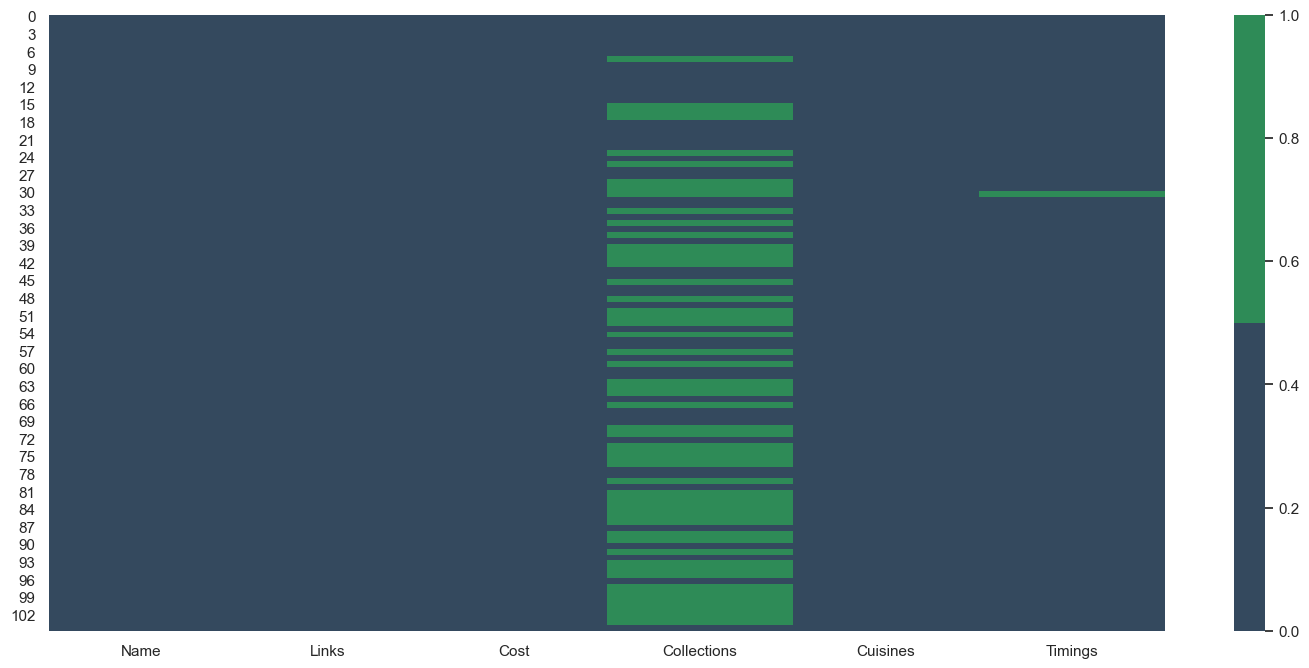

In [301]:
# Visualizing the missing values
plt.figure(figsize=(18,8))

colours = ['#34495E', 'seagreen'] 
sns.heatmap(df1.isnull(), cmap=sns.color_palette(colours))

<Axes: >

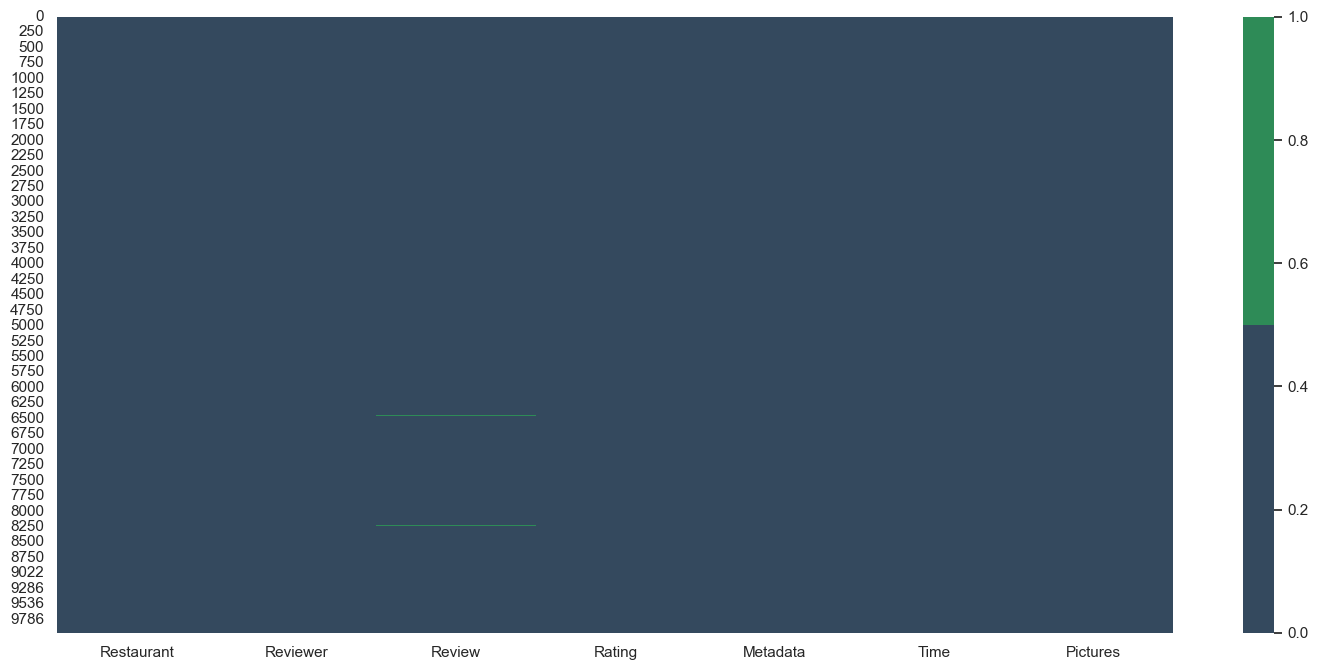

In [302]:
plt.figure(figsize=(18,8))
sns.heatmap(df2.isnull(), cmap=sns.color_palette(colours))

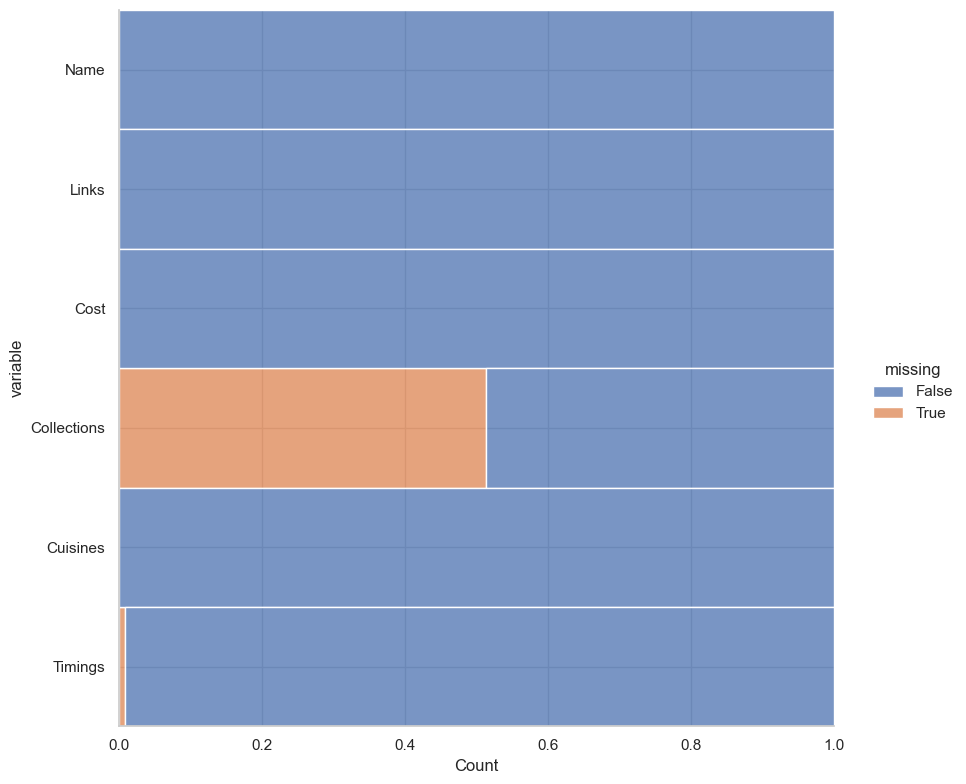

In [303]:
sns.displot(
    data=df1.isnull().melt(value_name='missing'),
    y='variable',
    hue='missing',
    multiple='fill',
    height=8,
    aspect=1.1
)

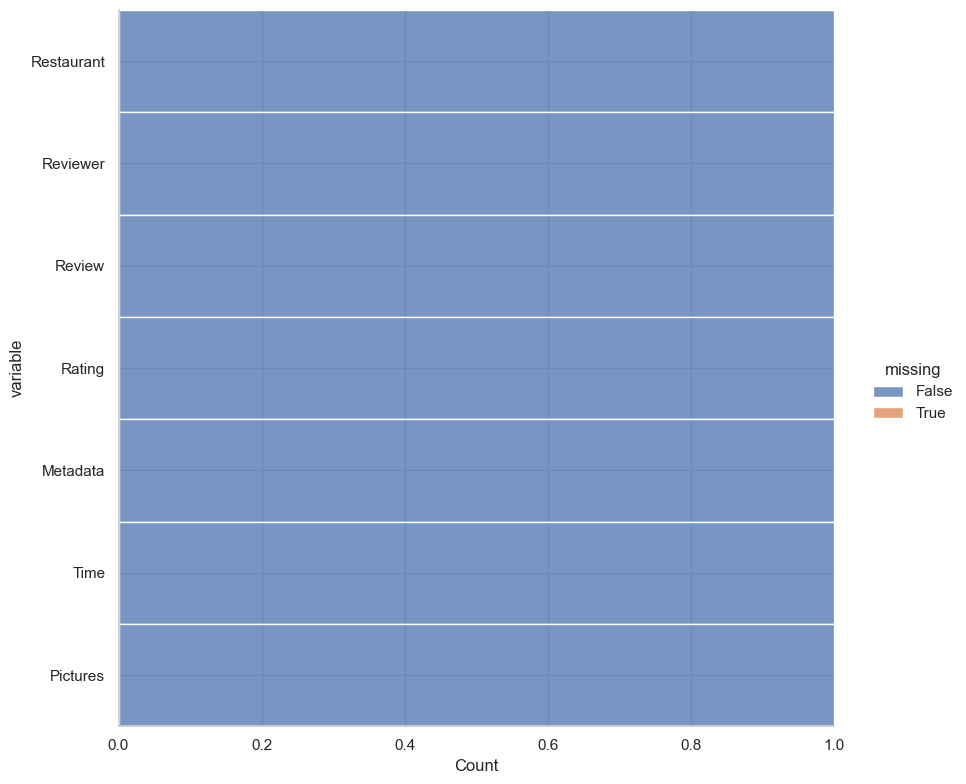

In [304]:
sns.displot(
    data=df2.isnull().melt(value_name='missing'),
    y='variable',
    hue='missing',
    multiple='fill',
    height=8,
    aspect=1.1
)

### What did you know about your dataset?

* We noticed that in the dataset1 the collections feature has more than 50% missing values.
* We also noticed that in the dataset2 the missing values of all columns are negligible <1%.

## ***2. Understanding Your Variables***

In [305]:
# Dataset Columns
columns1 = df1.columns
columns2 = df2.columns
print(columns1)
print(columns2)

Index(['Name', 'Links', 'Cost', 'Collections', 'Cuisines', 'Timings'], dtype='object')
Index(['Restaurant', 'Reviewer', 'Review', 'Rating', 'Metadata', 'Time',
       'Pictures'],
      dtype='object')


In [306]:
# Dataset Describe
df1.describe(include='all').T

,count,unique,top,freq
Name,105,105,Beyond Flavours,1
Links,105,105,https://www.zomato.com/hyderabad/beyond-flavou...,1
Cost,105,29,500,13
Collections,51,42,Food Hygiene Rated Restaurants in Hyderabad,4
Cuisines,105,92,"North Indian, Chinese",4
Timings,104,77,11 AM to 11 PM,6


In [307]:
# Dataset Describe
df2.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Restaurant,9964,100,Beyond Flavours,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Reviewer,9962,7446,Parijat Ray,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Review,9955,9364,good,237,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,9962,10,5,3832,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Metadata,9962,2477,1 Review,919,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time,9962,9782,5/5/2019 22:39,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pictures,9964.0,NaN,NaN,NaN,0.751305,2.574626,0.0,0.0,0.0,0.0,64.0


### Variables Description

**Restaurant Dataset**

Restaurant
Name of the restaurant (unique identifier). Used only for reference and interpretation, not for modeling.

Cost
Average cost for two people at the restaurant. Indicates pricing category (budget, mid-range, premium).

Cuisines
Types of cuisines served by the restaurant (e.g., North Indian, Chinese, Italian). Multi-label categorical variable used for grouping and encoding.

Collections
Special Zomato collections or tags assigned to the restaurant (e.g., “Trending This Week”, “Romantic Dining”). Contains high missing values and is not directly used for clustering.

Timings
Opening and closing hours of the restaurant. Used to derive operational features such as open duration, late-night service, or breakfast availability.

Pictures
Number of photos uploaded for the restaurant. Indicates visual engagement and marketing presence.

Total Review
Total number of customer reviews. Represents popularity and customer engagement.

Total Followers
Number of followers of the restaurant on the platform. Indicates brand recognition and customer interest.

**Review Dataset**

Restaurant
Name of the restaurant being reviewed. Used to link reviews to restaurant-level data.

Reviewer
Unique identifier or name of the reviewer. Not used in modeling; used only for reference.

Review
Textual customer feedback describing dining experience. Used for NLP preprocessing and sentiment analysis.

Rating
Numerical rating given by the customer (typically on a 1–5 scale). Indicates customer satisfaction.

Review Time / Date
Timestamp of when the review was posted. Used to extract:

Review_Year

Review_Month

Review_Hour
for time-based analysis.

Pictures
Number of images attached to the review. Reflects user engagement.

Total Review (Reviewer Level)
Total number of reviews written by the reviewer. Indicates reviewer activity.

Total Followers (Reviewer Level)
Number of followers the reviewer has on the platform. Indicates reviewer influence.

### Check Unique Values for each variable.

In [308]:
# Check Unique Values for each variable.
for cols in columns1:
    print(f"{cols} : {df1[cols].nunique()}")

Name : 105
Links : 105
Cost : 29
Collections : 42
Cuisines : 92
Timings : 77


In [309]:
# Check Unique Values for each variable.
for cols in columns2:
    print(f"{cols} : {df2[cols].nunique()}")

Restaurant : 100
Reviewer : 7446
Review : 9364
Rating : 10
Metadata : 2477
Time : 9782
Pictures : 36


## 3. ***Data Wrangling***

### Data Wrangling Code

In [310]:
# Write your code to make your dataset analysis ready.

#Creating copy of both the datasets.
hotels_ = df1.copy()
reviews_ = df2.copy()

In [311]:
# Cuisines
cuisine_list = (
    df1['Cuisines']
    .dropna()
    .str.split(',')
    .explode()
    .str.strip()
    .unique()
    .tolist()
)

#print(cuisine_list)

Indian = [
 'North Indian', 'South Indian', 'Biryani', 'Mughlai',
 'Andhra', 'Hyderabadi', 'Goan', 'North Eastern',
 'Modern Indian'
]
Asian = [
 'Chinese', 'Japanese', 'Thai', 'Indonesian',
 'Malaysian', 'Sushi'
]
Middle_Eastern = [
 'Lebanese', 'Arabian', 'Mediterranean', 'Kebab'
]
Western = [
 'Italian', 'American', 'European', 'Spanish',
 'Mexican', 'Burger', 'Pizza'
]
Fast_Food = [
 'Street Food', 'Fast Food', 'Wraps',
 'Momos', 'Finger Food'
]
Desserts = [
 'Desserts', 'Bakery', 'Ice Cream', 'Mithai',
 'Cafe', 'Juices', 'Beverages'
]
Healthy = [
 'Healthy Food', 'Salad', 'Seafood'
]
BBQ_Grill = [
 'BBQ'
]

cuisine_groups = {
    'Indian': Indian,
    'Asian': Asian,
    'Middle_Eastern': Middle_Eastern,
    'Western': Western,
    'Fast_Food': Fast_Food,
    'Desserts': Desserts,
    'Healthy': Healthy,
    'BBQ_Grill': BBQ_Grill
}

def map_cuisine_group(cuisines):
    if pd.isna(cuisines):
        return 'Unknown'
    cuisines = [c.strip() for c in cuisines.split(',')]
    groups = set()
    for g, clist in cuisine_groups.items():
        if any(c in clist for c in cuisines):
            groups.add(g)
    return ', '.join(groups) if groups else 'Others'

df1['Cuisine_Group'] = df1['Cuisines'].apply(map_cuisine_group)

# multi hot encoding for different cuisine groups
for group in cuisine_groups.keys():
    df1[f'is_{group}'] = df1['Cuisine_Group'].str.contains(group, na=False).astype(int)

# It gives the cuisine count
df1['cuisine_count'] = df1['Cuisines'].apply(
    lambda x: len(x.split(',')) if pd.notna(x) else 0
)

df1.drop(columns=['Cuisines','Cuisine_Group'],inplace=True)

df1.head()

,Name,Links,Cost,Collections,Timings,is_Indian,is_Asian,is_Middle_Eastern,is_Western,is_Fast_Food,is_Desserts,is_Healthy,is_BBQ_Grill,cuisine_count
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)",1,1,1,1,0,0,0,0,6
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,11 AM to 11 PM,1,1,0,0,0,0,0,0,3
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","11:30 AM to 4:30 PM, 6:30 PM to 11 PM",1,0,1,0,0,1,0,0,4
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,12 Noon to 2 AM,1,1,0,0,0,1,1,0,5
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,"1,200","Best Bars & Pubs, Food Hygiene Rated Restauran...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no...",1,1,1,0,0,0,0,0,5


In [312]:
# Links

# the only thing we derive from the links is the location which is hyderabad for every restaurant...

In [313]:
# Collections
#checking null values in Collections
missing_percentage = ((df1['Collections'].isnull().sum())/(len(df1['Collections'])))*100
print(f'Percentage of missing value in Collections is {round(missing_percentage, 2)}%')


#dropping collection column since has more than 50% of null values
# df1.drop('Collections', axis = 1, inplace = True)
# The Collections feature is editorial, high-cardinality, multi-label, and sparse, which makes it unsuitable for distance-based clustering algorithms. Including it would introduce noise, bias, and unstable clusters that do not reflect actual restaurant behavior or customer experience.

Percentage of missing value in Collections is 51.43%


In [314]:
#Timings

def time_to_hour(t):
    t = t.lower().strip()
    
    if 'noon' in t:
        return 12
    if 'midnight' in t:
        return 24
    
    m = re.search(r'(\d{1,2})(?::\d{2})?\s*(am|pm)', t)
    if not m:
        return None
    
    hour = int(m.group(1))
    mer = m.group(2)
    
    if mer == 'pm' and hour != 12:
        hour += 12
    if mer == 'am' and hour == 12:
        hour = 24
    
    return hour

def parse_timings(timing):
    if pd.isna(timing):
        return None, None, 0
    
    timing = timing.lower()
    timing = re.sub(r'\(.*?\)', '', timing)
    
    slots = timing.split(',')
    opens = []
    closes = []
    
    for s in slots:
        parts = s.split('to')
        if len(parts) != 2:
            continue
        
        o = time_to_hour(parts[0])
        c = time_to_hour(parts[1])
        
        if o is not None and c is not None:
            opens.append(o)
            closes.append(c)
    
    if not opens or not closes:
        return None, None, 0
    
    return min(opens), max(closes), len(slots)

df1[['open_hour', 'close_hour', 'num_slots']] = (
    df1['Timings']
    .apply(lambda x: pd.Series(parse_timings(x)))
)

df1['opens_early'] = (df1['open_hour'] <= 9).astype(int)

df1['breakfast_service'] = (df1['open_hour'] <= 8).astype(int)

df1['closes_late'] = (df1['close_hour'] >= 23).astype(int)

df1['late_night'] = (df1['close_hour'] >= 24).astype(int)

df1['open_duration_hours'] = (
    df1['close_hour'] - df1['open_hour']
)

df1['split_shift'] = (df1['num_slots'] > 1).astype(int)

df1[['open_duration_hours']] = df1[['open_duration_hours']].fillna(0)

df1.head()

,Name,Links,Cost,Collections,Timings,is_Indian,is_Asian,is_Middle_Eastern,is_Western,is_Fast_Food,...,cuisine_count,open_hour,close_hour,num_slots,opens_early,breakfast_service,closes_late,late_night,open_duration_hours,split_shift
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)",1,1,1,1,0,...,6,12.0,23.0,2.0,0,0,1,0,11.0,1
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,11 AM to 11 PM,1,1,0,0,0,...,3,11.0,23.0,1.0,0,0,1,0,12.0,0
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","11:30 AM to 4:30 PM, 6:30 PM to 11 PM",1,0,1,0,0,...,4,11.0,23.0,2.0,0,0,1,0,12.0,1
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,12 Noon to 2 AM,1,1,0,0,0,...,5,12.0,2.0,1.0,0,0,0,0,-10.0,0
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,"1,200","Best Bars & Pubs, Food Hygiene Rated Restauran...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no...",1,1,1,0,0,...,5,12.0,24.0,2.0,0,0,1,1,12.0,1


In [315]:
#Code to make Restaurant information Dataset analysis ready.

# changing the data type of the cost function (removing commas and then converting to integer value)
df1['Cost'] = df1['Cost'].str.replace(",","").astype('int64')

In [316]:
df1.drop(columns=["Links","Collections","Timings"],inplace=True)

In [317]:
df1.head()

,Name,Cost,is_Indian,is_Asian,is_Middle_Eastern,is_Western,is_Fast_Food,is_Desserts,is_Healthy,is_BBQ_Grill,cuisine_count,open_hour,close_hour,num_slots,opens_early,breakfast_service,closes_late,late_night,open_duration_hours,split_shift
0,Beyond Flavours,800,1,1,1,1,0,0,0,0,6,12.0,23.0,2.0,0,0,1,0,11.0,1
1,Paradise,800,1,1,0,0,0,0,0,0,3,11.0,23.0,1.0,0,0,1,0,12.0,0
2,Flechazo,1300,1,0,1,0,0,1,0,0,4,11.0,23.0,2.0,0,0,1,0,12.0,1
3,Shah Ghouse Hotel & Restaurant,800,1,1,0,0,0,1,1,0,5,12.0,2.0,1.0,0,0,0,0,-10.0,0
4,Over The Moon Brew Company,1200,1,1,1,0,0,0,0,0,5,12.0,24.0,2.0,0,0,1,1,12.0,1


***Code to make Reviews of restaurant Dataset analysis ready.***

In [318]:
# Only drops the row if 'Review' is null
df2.dropna(subset=['Review'], inplace=True)
print(f"Null Count in df2 : {df2.isnull().sum()}")

Null Count in df2 : Restaurant    0
Reviewer      0
Review        0
Rating        0
Metadata      0
Time          0
Pictures      0
dtype: int64


In [319]:
#We saw that the Data Type for values in Rating is  <class 'str'> so we need to convert it into INT.
print(f"The Data Type for values in Rating is  {type(df2['Rating'][0])}.")
df2['Rating'].value_counts().reset_index().rename(columns={'index':'Rating','Rating':'Count of Ratings'})

The Data Type for values in Rating is  <class 'str'>.


,Count of Ratings,count
0,5,3826
1,4,2373
2,1,1735
3,3,1192
4,2,684
5,4.5,69
6,3.5,47
7,2.5,19
8,1.5,9
9,Like,1


In [320]:
#Converting "Like" value to zero first.
df2['Rating'].where(df2['Rating']!='Like',0,inplace=True)

#Converting DataType of Rating Column into Float.
df2['Rating'] = df2['Rating'].astype('float')

#Substituting 0 with median now.
df2['Rating'].where(df2['Rating']!=0,df2.Rating.median(),inplace=True)

print(f"The Data Type for values in Rating is  {type(df2['Rating'][0])}.")

The Data Type for values in Rating is  <class 'numpy.float64'>.


C:\Users\sreya\AppData\Local\Temp\ipykernel_18596\2257505965.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df2['Rating'].where(df2['Rating']!='Like',0,inplace=True)
C:\Users\sreya\AppData\Local\Temp\ipykernel_18596\2257505965.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

In [321]:
#We are Extracting Total Review and Total Followers for every Reviewer	from Metadata Column.
df2[['Total Review', 'Total Followers']] = df2['Metadata'].str.split(',', n=2, expand=True)[[0, 1]]
df2['Total Review'] = pd.to_numeric(df2['Total Review'].str.split(' ').str[0])
df2['Total Followers'] = pd.to_numeric(df2['Total Followers'].str.split(' ').str[1])

In [322]:
#Filling null values in 'Total Followers' column with zero and in 'Review' column with 'NA'.
df2.fillna({'Review':'NA','Total Followers':0},inplace=True)

In [323]:
#we'll go ahead and drop 'Reviewer' column , since all values corresponding to this column are null in dataset
df2[df2['Reviewer'].isnull()]

,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,Total Review,Total Followers


In [324]:
df2['Time'] = pd.to_datetime(df2['Time'])

#Extracting Year,Month and Hour from Time column of Dataset for better analysis.
df2['Review_Year']=df2['Time'].dt.year
df2['Review_Month']=df2['Time'].dt.month
df2['Review_Hour']=df2['Time'].dt.hour

In [325]:
df2.drop(columns=['Metadata','Time'],inplace=True)

In [326]:
df2.head()

,Restaurant,Reviewer,Review,Rating,Pictures,Total Review,Total Followers,Review_Year,Review_Month,Review_Hour
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5.0,0,1,2.0,2019,5,15
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5.0,0,3,2.0,2019,5,14
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5.0,0,2,3.0,2019,5,22
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5.0,0,1,1.0,2019,5,22
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5.0,0,3,2.0,2019,5,21


In [327]:
#merging both data frame and combining into 1 dataframe named hotel_review .
df1 = df1.rename(columns = {'Name':'Restaurant'})
hotel_review= df1.merge(df2, on = 'Restaurant')

In [328]:
hotel_review.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9955 entries, 0 to 9954
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Restaurant           9955 non-null   object 
 1   Cost                 9955 non-null   int64  
 2   is_Indian            9955 non-null   int64  
 3   is_Asian             9955 non-null   int64  
 4   is_Middle_Eastern    9955 non-null   int64  
 5   is_Western           9955 non-null   int64  
 6   is_Fast_Food         9955 non-null   int64  
 7   is_Desserts          9955 non-null   int64  
 8   is_Healthy           9955 non-null   int64  
 9   is_BBQ_Grill         9955 non-null   int64  
 10  cuisine_count        9955 non-null   int64  
 11  open_hour            9655 non-null   float64
 12  close_hour           9655 non-null   float64
 13  num_slots            9955 non-null   float64
 14  opens_early          9955 non-null   int64  
 15  breakfast_service    9955 non-null   i

***Creating a restaurant dataframe***

In [329]:
restaurant_df = hotel_review.groupby('Restaurant').agg({
    'Cost': 'mean',
    'Rating': 'mean',
    'Pictures': 'mean',
    'Total Review': 'mean',
    'Total Followers': 'mean',
    'cuisine_count': 'first',
    'is_Indian': 'first',
    'is_Asian': 'first',
    'is_Middle_Eastern': 'first',
    'is_Western': 'first',
    'is_Fast_Food': 'first',
    'is_Desserts': 'first',
    'is_Healthy': 'first',
    'is_BBQ_Grill': 'first',
    'opens_early': 'first',
    'breakfast_service': 'first',
    'closes_late': 'first',
    'late_night': 'first',
    'open_duration_hours': 'first',
    'split_shift': 'first'
}).reset_index()

### What all manipulations have you done and insights you found?

* Derived Cuisine 

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

In [330]:
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (8,5)

#### Chart - 1

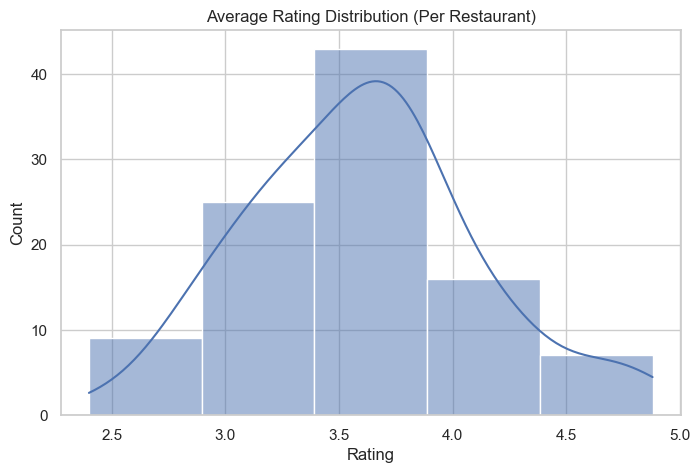

In [331]:
# Chart - 1 visualization code
sns.histplot(restaurant_df['Rating'], bins=5, kde=True)
plt.title("Average Rating Distribution (Per Restaurant)")
plt.show()

##### 1. Why did you pick the specific chart?

To understand the overall distribution and skewness of customer ratings.

##### 2. What is/are the insight(s) found from the chart?

Most ratings are concentrated between 3 and 5, indicating generally positive customer feedback.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Helps validate overall platform satisfaction and motivates deeper sentiment validation.

#### Chart - 2

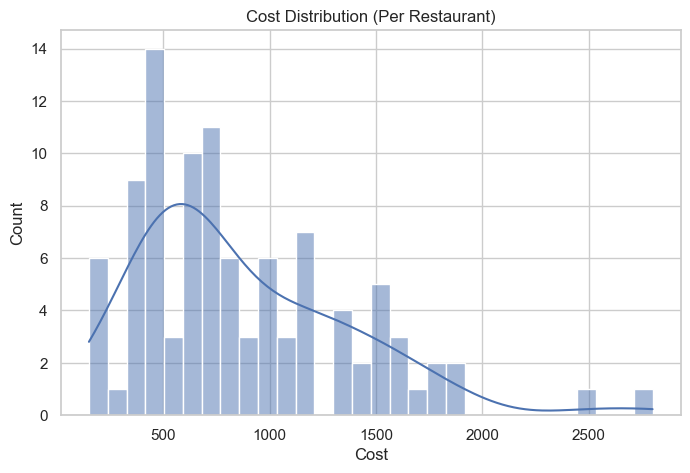

In [332]:
# Chart - 2 visualization code
sns.histplot(restaurant_df['Cost'], bins=30, kde=True)
plt.title("Cost Distribution (Per Restaurant)")
plt.show()

##### 1. Why did you pick the specific chart?

Histograms are ideal for understanding price segmentation.

##### 2. What is/are the insight(s) found from the chart?

Most restaurants fall into low-to-mid price ranges, with fewer premium listings.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Enables targeted pricing-based recommendations.

#### Chart - 3

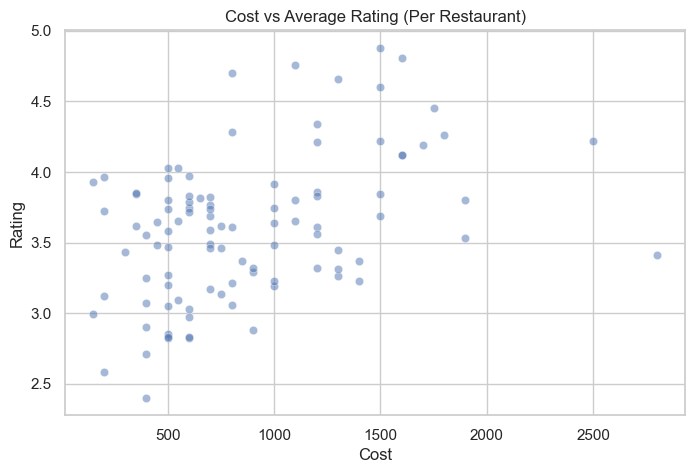

In [333]:
# Chart - 3 visualization code
sns.scatterplot(x='Cost', y='Rating', data=restaurant_df, alpha=0.5)
plt.title("Cost vs Average Rating (Per Restaurant)")
plt.show()

##### 1. Why did you pick the specific chart?

To study relationship between pricing and customer satisfaction.

##### 2. What is/are the insight(s) found from the chart?

Higher cost does not always guarantee higher ratings.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Highlights value-for-money restaurants.

#### Chart - 4

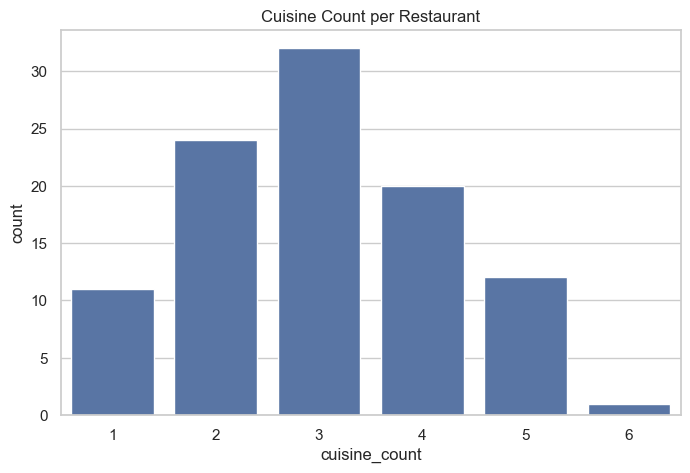

In [334]:
# Chart - 4 visualization code
sns.countplot(x='cuisine_count', data=restaurant_df)
plt.title("Cuisine Count per Restaurant")
plt.show()

##### 1. Why did you pick the specific chart?

Shows specialization vs multi-cuisine.

##### 2. What is/are the insight(s) found from the chart?

Most restaurants serve 1–2 cuisines.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Helps design niche vs variety offerings.

#### Chart - 5

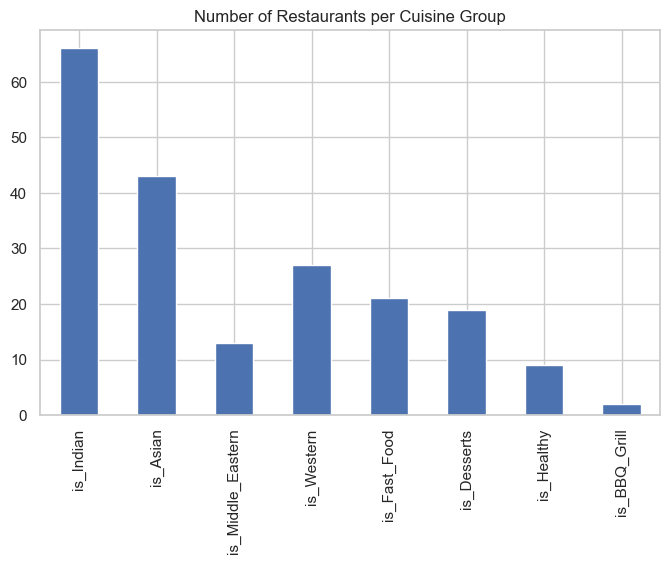

In [335]:
# Chart - 5 visualization code
cuisine_cols = [
    'is_Indian','is_Asian','is_Middle_Eastern','is_Western',
    'is_Fast_Food','is_Desserts','is_Healthy','is_BBQ_Grill'
]

restaurant_df[cuisine_cols].sum().plot(kind='bar')
plt.title("Number of Restaurants per Cuisine Group")
plt.show()


##### 1. Why did you pick the specific chart?

Category comparison.

##### 2. What is/are the insight(s) found from the chart?

Indian & Fast Food dominate.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Guides expansion & onboarding strategy.

#### Chart - 6

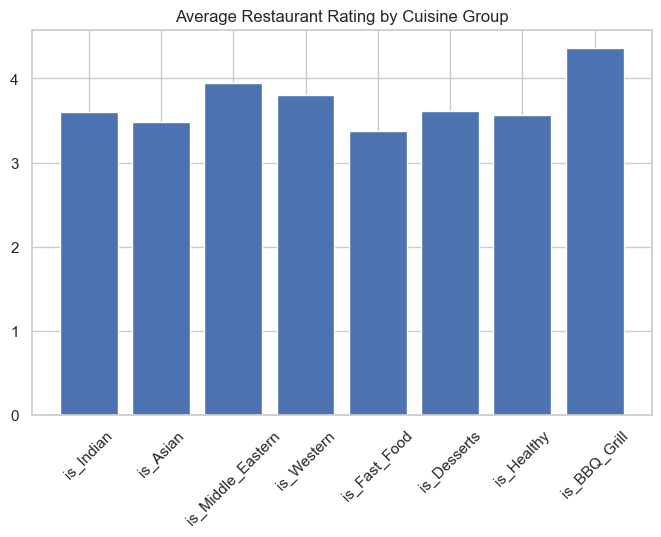

In [336]:
# Chart - 6 visualization code
avg_rating = {
    c: restaurant_df[restaurant_df[c] == 1]['Rating'].mean()
    for c in cuisine_cols
}

plt.bar(avg_rating.keys(), avg_rating.values())
plt.xticks(rotation=45)
plt.title("Average Restaurant Rating by Cuisine Group")
plt.show()

##### 1. Why did you pick the specific chart?

To compare performance across cuisine segments.

##### 2. What is/are the insight(s) found from the chart?

Certain cuisine groups consistently receive higher ratings.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Enables promotion of high-performing cuisines.

#### Chart - 7

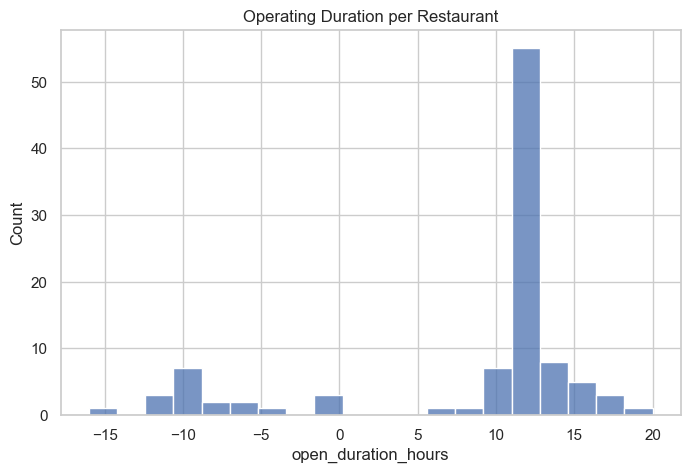

In [337]:
# Chart - 7 visualization code
sns.histplot(restaurant_df['open_duration_hours'], bins=20)
plt.title("Operating Duration per Restaurant")
plt.show()


##### 1. Why did you pick the specific chart?

Operational behavior.

##### 2. What is/are the insight(s) found from the chart?

Many restaurants operate long hours.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Identify late-hour service opportunities.

#### Chart - 8

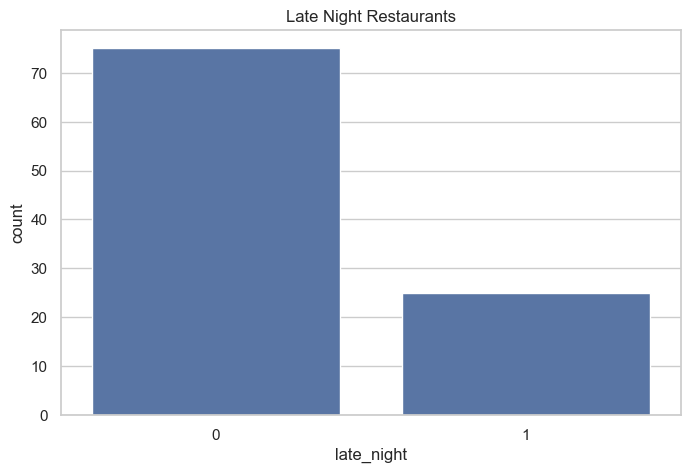

In [338]:
# Chart - 8 visualization code
sns.countplot(x='late_night', data=restaurant_df)
plt.title("Late Night Restaurants")
plt.show()

##### 1. Why did you pick the specific chart?

Binary operational analysis.

##### 2. What is/are the insight(s) found from the chart?

Few restaurants operate post-midnight.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Promote late-night options.

#### Chart - 9

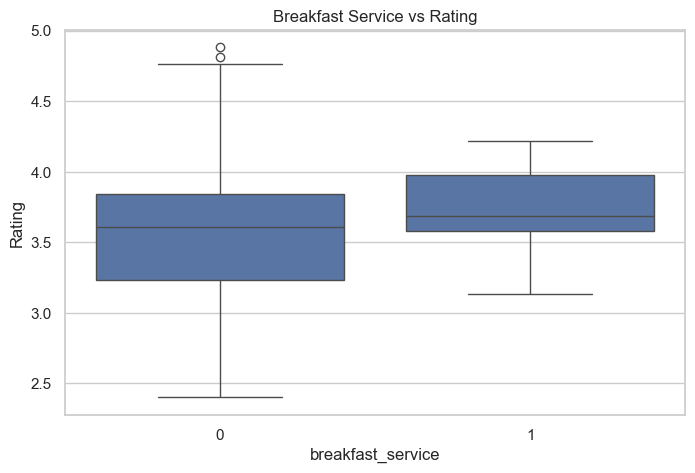

In [339]:
# Chart - 9 visualization code
sns.boxplot(x='breakfast_service', y='Rating', data=restaurant_df)
plt.title("Breakfast Service vs Rating")
plt.show()

##### 1. Why did you pick the specific chart?

Compare quality by service timing.

##### 2. What is/are the insight(s) found from the chart?

Breakfast places maintain strong ratings.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Encourage breakfast menus.

#### Chart - 10

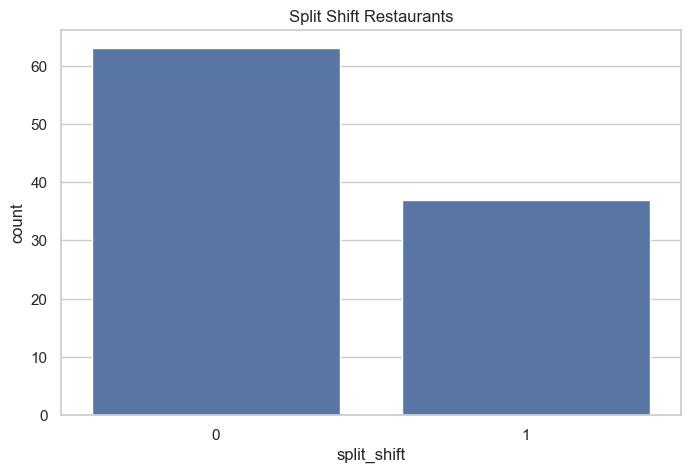

In [340]:
# Chart - 10 visualization code
sns.countplot(x='split_shift', data=restaurant_df)
plt.title("Split Shift Restaurants")
plt.show()

##### 1. Why did you pick the specific chart?

Understand operational models.

##### 2. What is/are the insight(s) found from the chart?

Many operate in lunch–dinner shifts.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Helps workforce & delivery planning.

#### Chart - 11

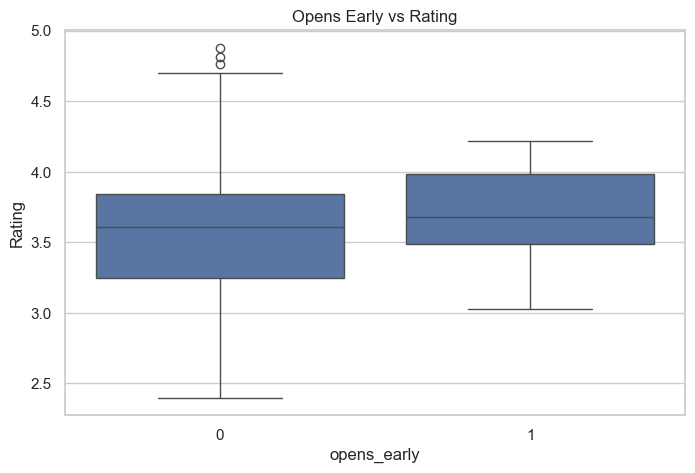

In [341]:
# Chart - 11 visualization code
sns.boxplot(x='opens_early', y='Rating', data=restaurant_df)
plt.title("Opens Early vs Rating")
plt.show()

##### 1. Why did you pick the specific chart?

Compare early-opening performance.

##### 2. What is/are the insight(s) found from the chart?

Early-openers maintain solid ratings.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Supports breakfast café targeting.

#### Chart - 12

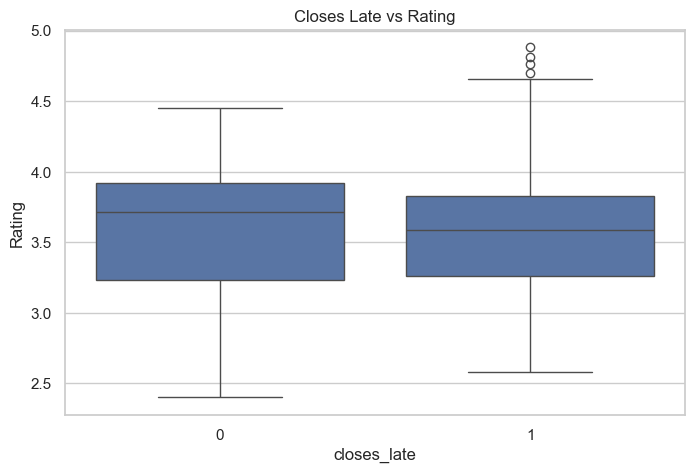

In [342]:
# Chart - 12 visualization code
sns.boxplot(x='closes_late', y='Rating', data=restaurant_df)
plt.title("Closes Late vs Rating")
plt.show()

##### 1. Why did you pick the specific chart?

Night operations analysis.

##### 2. What is/are the insight(s) found from the chart?

Late-closing restaurants perform competitively.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Promote late-night dining.

#### Chart - 13

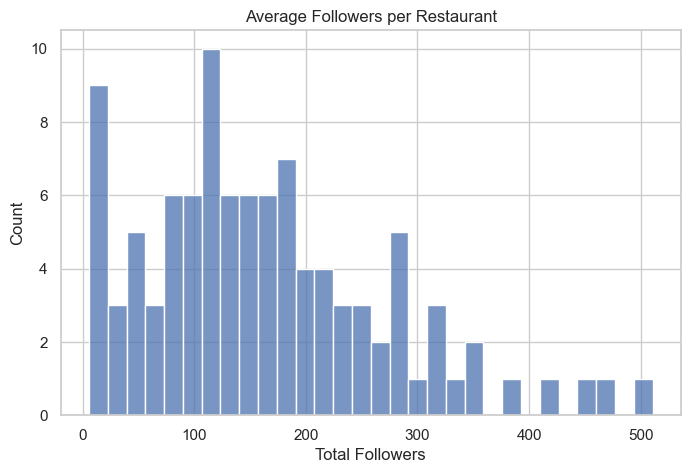

In [343]:
# Chart - 13 visualization code
sns.histplot(restaurant_df['Total Followers'], bins=30)
plt.title("Average Followers per Restaurant")
plt.show()

##### 1. Why did you pick the specific chart?

Reviewer credibility distribution.

##### 2. What is/are the insight(s) found from the chart?

Most restaurants are reviewed by low-follower users.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Identify outlets with influencer attention.

#### Chart - 14 - Correlation Heatmap

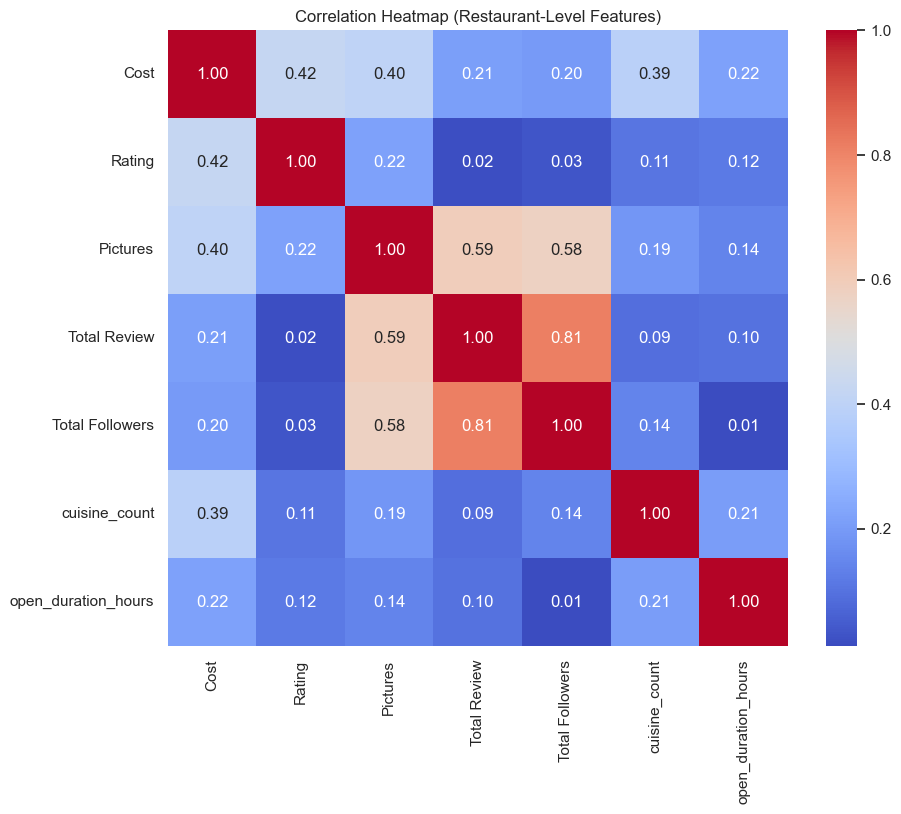

In [344]:
# Correlation Heatmap visualization code
# Select only numerical features for correlation
num_cols = [
    'Cost', 'Rating', 'Pictures', 'Total Review', 'Total Followers',
    'cuisine_count', 'open_duration_hours'
]

corr = restaurant_df[num_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap (Restaurant-Level Features)")
plt.show()

##### 1. Why did you pick the specific chart?

A heatmap is ideal for visualizing pairwise correlations among multiple numerical features at once, helping identify relationships and redundancy.

##### 2. What is/are the insight(s) found from the chart?

* Rating often shows weak correlation with Cost, indicating that expensive restaurants are not necessarily better rated.
* Strong correlation may appear between Total Review and Total Followers, showing that more active reviewers also tend to have more followers.
* Operational features like open_duration_hours may show low correlation with rating, suggesting service quality is not driven solely by operating hours.

#### Chart - 15 - Pair Plot

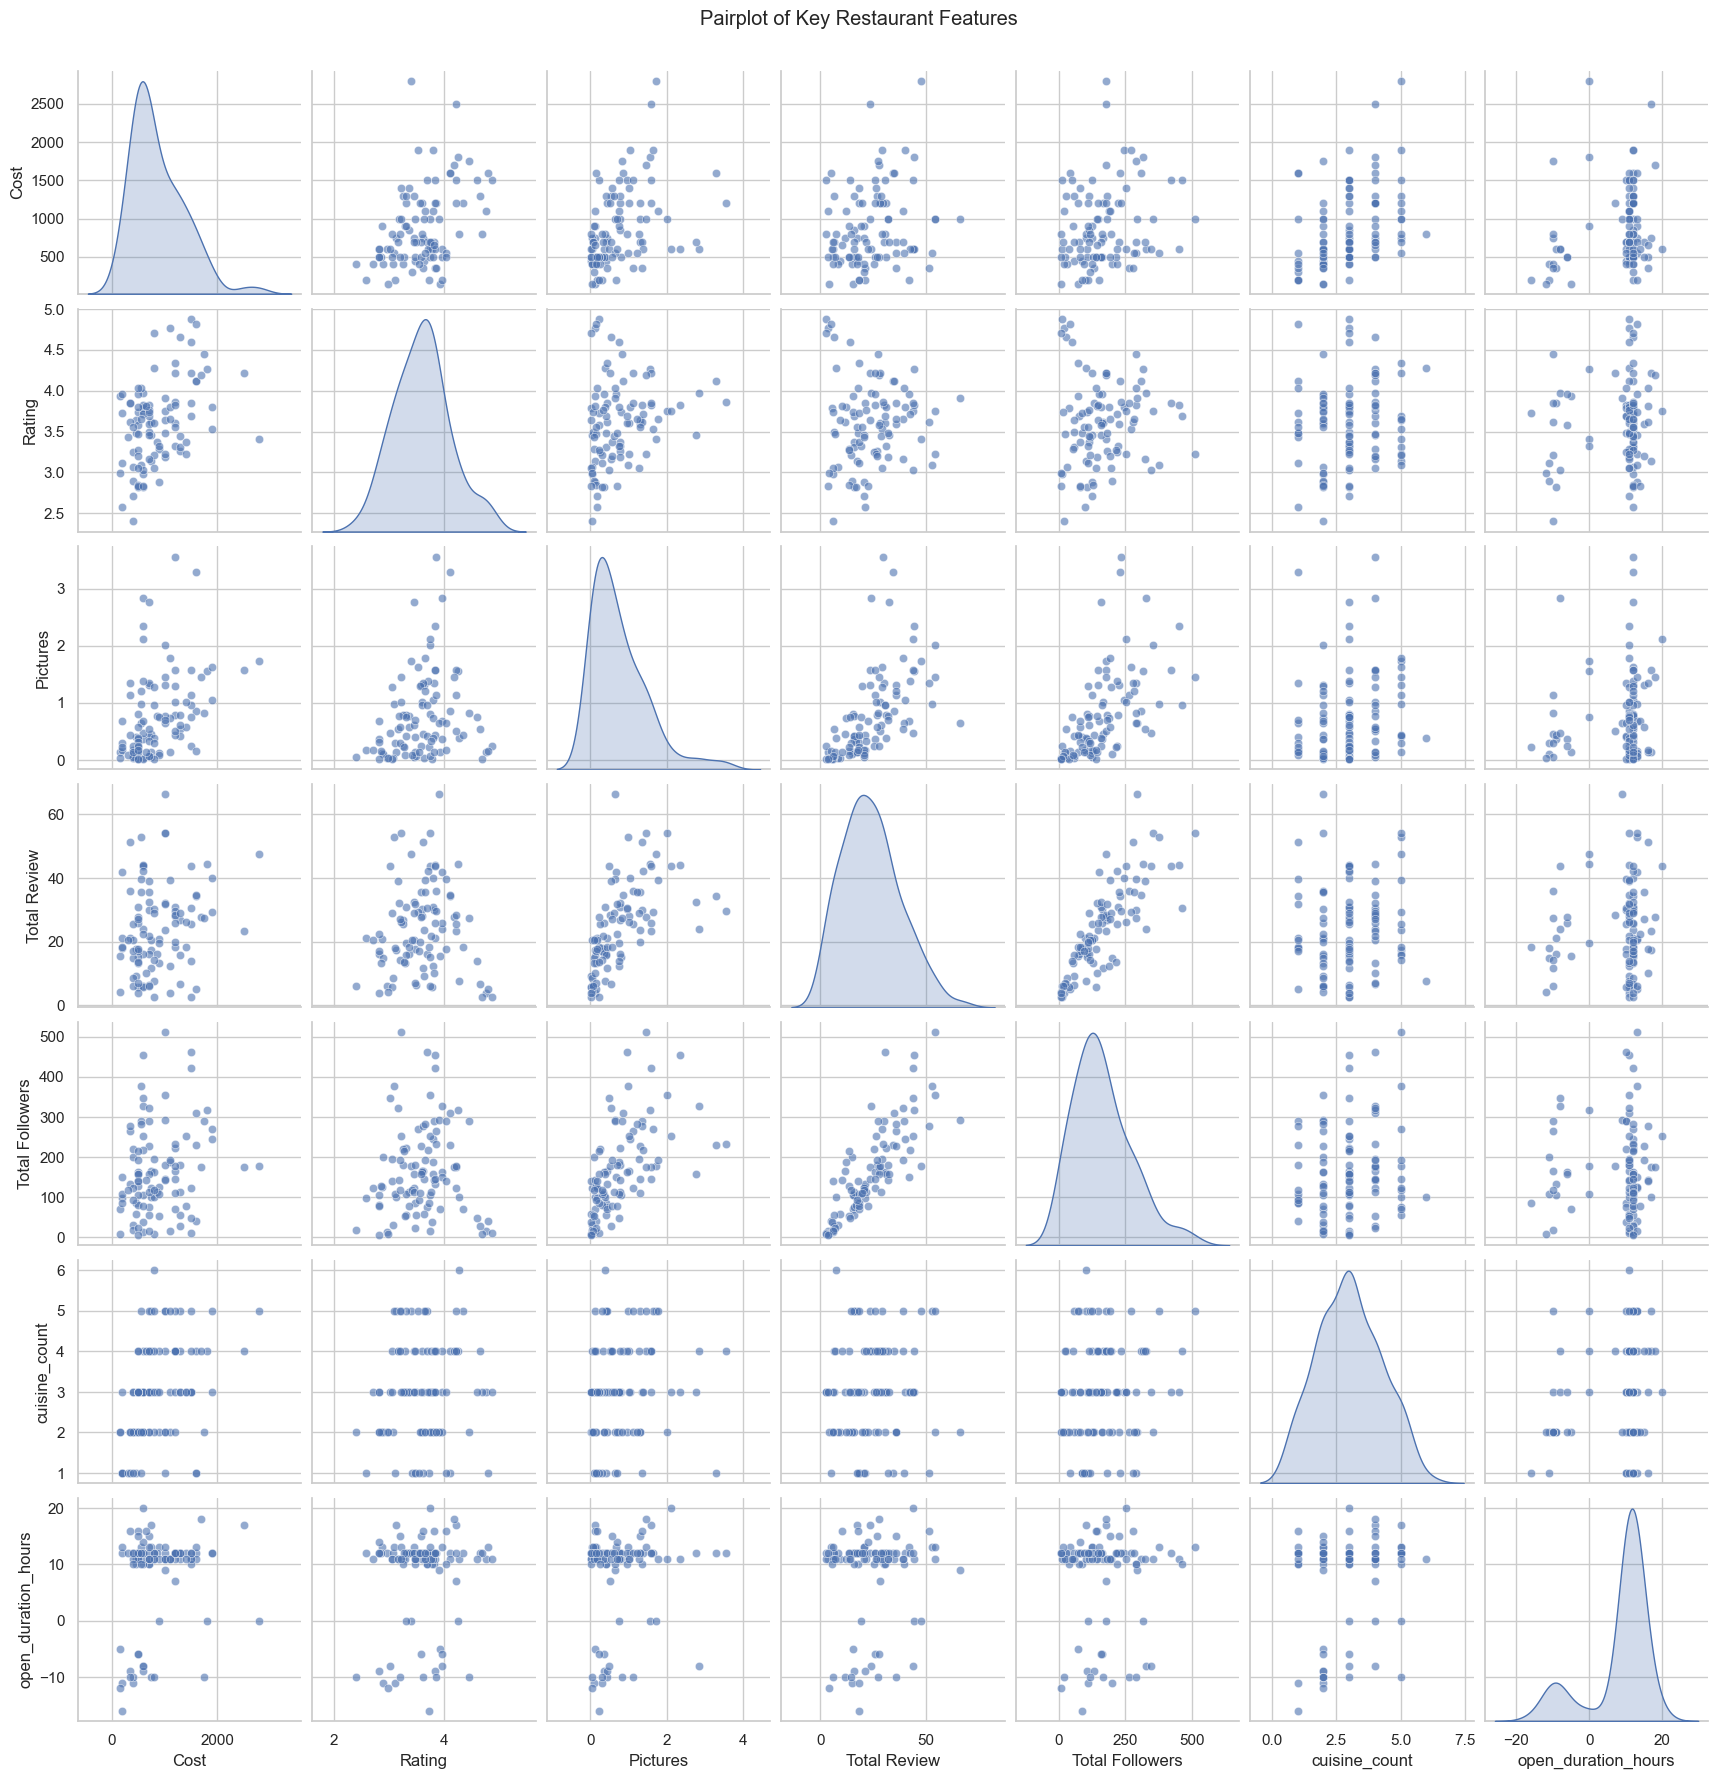

In [345]:
# Pair Plot visualization code
# Pairplot on key numerical features
sns.pairplot(
    restaurant_df[num_cols],
    diag_kind='kde',
    plot_kws={'alpha': 0.6}
)
plt.suptitle("Pairplot of Key Restaurant Features", y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

A pairplot provides multiple scatter plots and distributions simultaneously, making it excellent for detecting:
- Relationships
- Clusters
- Outliers
- Non-linear patterns

##### 2. What is/are the insight(s) found from the chart?

- Some features show no strong linear relationship, validating the need for unsupervised clustering.

- Restaurants with similar ratings can differ widely in cost and operating hours, indicating multiple business segments.

- Outliers (very high cost or unusually high follower influence) become visually identifiable.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

We test whether restaurant pricing has a statistically significant effect on average customer ratings.
- H₀ (Null Hypothesis): There is no significant difference in ratings between low-cost and high-cost restaurants.
- H₁ (Alternative Hypothesis): There is a significant difference in ratings between low-cost and high-cost restaurants.

#### 2. Perform an appropriate statistical test.

In [346]:
# Perform Statistical Test to obtain P-Value
from scipy.stats import ttest_ind

# Create cost-based groups using median
median_cost = restaurant_df['Cost'].median()
low_cost = restaurant_df[restaurant_df['Cost'] <= median_cost]['Rating']
high_cost = restaurant_df[restaurant_df['Cost'] > median_cost]['Rating']

t_stat, p_value = ttest_ind(low_cost, high_cost, equal_var=False)

t_stat, p_value

(np.float64(-3.7633884038115193), np.float64(0.000292582845593512))

##### Which statistical test have you done to obtain P-Value?

Independent Two-Sample t-test
(Comparing mean ratings of two independent groups: low-cost vs high-cost restaurants)

##### Why did you choose the specific statistical test?

Helps identify whether premium pricing actually leads to higher perceived quality or whether affordable restaurants can compete equally in customer satisfaction.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

We test whether restaurants operating late at night differ in ratings compared to others.
- H₀: There is no significant difference in ratings between late-night and non-late-night restaurants.
- H₁: There is a significant difference in ratings between late-night and non-late-night restaurants.

#### 2. Perform an appropriate statistical test.

In [347]:
# Perform Statistical Test to obtain P-Value
late = restaurant_df[restaurant_df['late_night'] == 1]['Rating']
non_late = restaurant_df[restaurant_df['late_night'] == 0]['Rating']

t_stat, p_value = ttest_ind(late, non_late, equal_var=False)

t_stat, p_value

(np.float64(0.3221645000648978), np.float64(0.7489670966445542))

##### Which statistical test have you done to obtain P-Value?

Independent Two-Sample t-test

##### Why did you choose the specific statistical test?

If significant, Zomato can prioritize promoting late-night restaurants in nighttime demand windows.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

We examine whether restaurants that offer breakfast have significantly different ratings compared to those that do not.
- H₀: Breakfast service has no effect on restaurant ratings.
- H₁: Restaurants offering breakfast have significantly different ratings.

#### 2. Perform an appropriate statistical test.

In [348]:
# Perform Statistical Test to obtain P-Value
breakfast = restaurant_df[restaurant_df['breakfast_service'] == 1]['Rating']
no_breakfast = restaurant_df[restaurant_df['breakfast_service'] == 0]['Rating']

t_stat, p_value = ttest_ind(breakfast, no_breakfast, equal_var=False)

t_stat, p_value

(np.float64(0.9511002661986977), np.float64(0.3584723562569294))

##### Which statistical test have you done to obtain P-Value?

Independent Two-Sample t-test

##### Why did you choose the specific statistical test?

Helps restaurants decide whether expanding into breakfast service can enhance perceived quality.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [349]:
# Handling Missing Values & Missing Value Imputation
hotel_review.isnull().sum()

Restaurant               0
Cost                     0
is_Indian                0
is_Asian                 0
is_Middle_Eastern        0
is_Western               0
is_Fast_Food             0
is_Desserts              0
is_Healthy               0
is_BBQ_Grill             0
cuisine_count            0
open_hour              300
close_hour             300
num_slots                0
opens_early              0
breakfast_service        0
closes_late              0
late_night               0
open_duration_hours      0
split_shift              0
Reviewer                 0
Review                   0
Rating                   0
Pictures                 0
Total Review             0
Total Followers          0
Review_Year              0
Review_Month             0
Review_Hour              0
dtype: int64

In [350]:
hotel_review = hotel_review.dropna(subset=['Review', 'Rating'])

In [351]:
hotel_review['Total Followers'] = hotel_review['Total Followers'].fillna(0)
hotel_review['Total Review'] = hotel_review['Total Review'].fillna(0)

In [352]:
num_cols = ['Cost', 'Rating', 'open_duration_hours']

for col in num_cols:
    restaurant_df[col] = restaurant_df[col].fillna(restaurant_df[col].median())

In [353]:
binary_cols = [
    'late_night','breakfast_service','opens_early',
    'closes_late','split_shift'
]

restaurant_df[binary_cols] = restaurant_df[binary_cols].fillna(0)

In [354]:
cuisine_cols = [
    'is_Indian','is_Asian','is_Middle_Eastern','is_Western',
    'is_Fast_Food','is_Desserts','is_Healthy','is_BBQ_Grill'
]

restaurant_df[cuisine_cols] = restaurant_df[cuisine_cols].fillna(0)

In [355]:
restaurant_df.isnull().sum()

Restaurant             0
Cost                   0
Rating                 0
Pictures               0
Total Review           0
Total Followers        0
cuisine_count          0
is_Indian              0
is_Asian               0
is_Middle_Eastern      0
is_Western             0
is_Fast_Food           0
is_Desserts            0
is_Healthy             0
is_BBQ_Grill           0
opens_early            0
breakfast_service      0
closes_late            0
late_night             0
open_duration_hours    0
split_shift            0
dtype: int64

#### What all missing value imputation techniques have you used and why did you use those techniques?

In this project, missing values were handled using feature-specific imputation strategies rather than applying a single generic method. The choice of each technique was based on the type of feature, its business meaning, and its impact on clustering and analysis.
- Row Deletion for Critical Fields (Listwise Deletion)
- Median Imputation for Numerical Features
- Zero Imputation for Binary / Flag Variables
- Zero Imputation for Cuisine Group Indicators
- Default Value Imputation for Reviewer Metadata

### 2. Handling Outliers

In [356]:
# Handling Outliers & Outlier treatments
restaurant_df.describe()

,Cost,Rating,Pictures,Total Review,Total Followers,cuisine_count,is_Indian,is_Asian,is_Middle_Eastern,is_Western,is_Fast_Food,is_Desserts,is_Healthy,is_BBQ_Grill,opens_early,breakfast_service,closes_late,late_night,open_duration_hours,split_shift
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.00000,100.000000,100.000000,100.00000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,872.000000,3.601929,0.760124,24.013861,163.514002,3.010000,0.660000,0.43000,0.130000,0.270000,0.21000,0.190000,0.090000,0.020000,0.120000,0.100000,0.690000,0.250000,8.270000,0.370000
std,505.940468,0.508102,0.737294,13.610378,109.406118,1.210184,0.476095,0.49757,0.337998,0.446196,0.40936,0.394277,0.287623,0.140705,0.326599,0.301511,0.464823,0.435194,8.293669,0.485237
min,150.000000,2.400000,0.010000,2.520000,5.620000,1.000000,0.000000,0.00000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-16.000000,0.000000
25%,500.000000,3.245000,0.170000,14.825000,85.540000,2.000000,0.000000,0.00000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,10.000000,0.000000
50%,700.000000,3.615000,0.560000,22.143737,144.505000,3.000000,1.000000,0.00000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,11.000000,0.000000
75%,1200.000000,3.846250,1.130000,31.185000,223.832500,4.000000,1.000000,1.00000,0.000000,1.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.250000,12.000000,1.000000
max,2800.000000,4.880000,3.560000,66.280000,510.680000,6.000000,1.000000,1.00000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,20.000000,1.000000


In [357]:
def cap_outliers_iqr(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df[col] = df[col].clip(lower, upper)

for col in ['Cost','open_duration_hours','Total Followers','Total Review']:
    cap_outliers_iqr(restaurant_df, col)

In [358]:
restaurant_df['Cost'] = restaurant_df['Cost'].clip(
    restaurant_df['Cost'].quantile(0.01),
    restaurant_df['Cost'].quantile(0.99)
)

restaurant_df['Total Followers'] = restaurant_df['Total Followers'].clip(
    restaurant_df['Total Followers'].quantile(0.01),
    restaurant_df['Total Followers'].quantile(0.99)
)

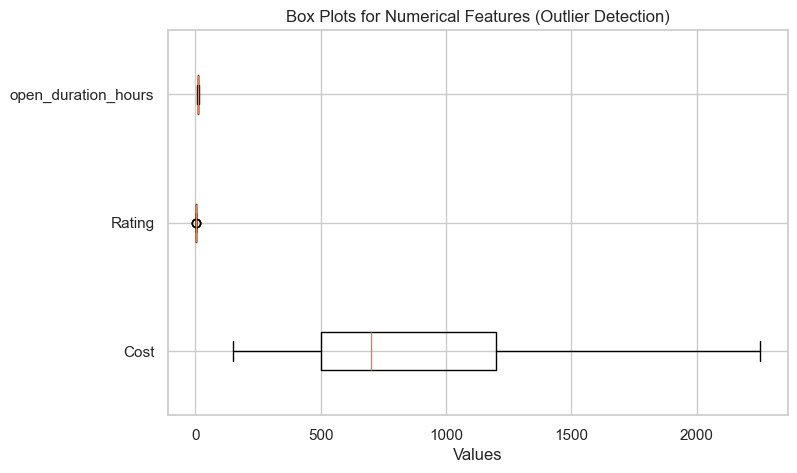

In [359]:
plt.figure()
plt.boxplot([restaurant_df[col] for col in num_cols], vert=False)
plt.yticks(range(1, len(num_cols) + 1), num_cols)
plt.title("Box Plots for Numerical Features (Outlier Detection)")
plt.xlabel("Values")
plt.show()

##### What all outlier treatment techniques have you used and why did you use those techniques?

- Interquartile Range (IQR) Method
- Winsorization (Capping Instead of Removing)

### 3. Categorical Encoding


***Already done in data wrangling section!!***

#### What all categorical encoding techniques have you used & why did you use those techniques?

- Binary Encoding (Multi-Hot Encoding)
- One-Hot Encoding (Conceptually Applied Through Grouping)

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

In [360]:
hotel_review['Review']

0       The ambience was good, food was quite good . h...
1       Ambience is too good for a pleasant evening. S...
2       A must try.. great food great ambience. Thnx f...
3       Soumen das and Arun was a great guy. Only beca...
4       Food is good.we ordered Kodi drumsticks and ba...
                              ...                        
9950    Madhumathi Mahajan Well to start with nice cou...
9951    This place has never disappointed us.. The foo...
9952    Bad rating is mainly because of "Chicken Bone ...
9953    I personally love and prefer Chinese Food. Had...
9954    Checked in here to try some delicious chinese ...
Name: Review, Length: 9955, dtype: object

#### 1. Expand Contraction

In [361]:
# Expand Contraction
contractions = {
    "can't": "cannot", "won't": "will not", "n't": " not",
    "'re": " are", "'s": " is", "'d": " would",
    "'ll": " will", "'t": " not", "'ve": " have", "'m": " am"
}

def expand_contractions(text):
    for key, value in contractions.items():
        text = re.sub(key, value, text)
    return text

hotel_review['Review'] = hotel_review['Review'].apply(expand_contractions)

#### 2. Lower Casing

In [362]:
# Lower Casing
hotel_review['Review'] = hotel_review['Review'].str.lower()

#### 3. Removing Punctuations

In [363]:
# Remove Punctuations
import string

def remove_punctuation(text):
    return text.translate(str.maketrans('', '', string.punctuation))

hotel_review['Review'] = hotel_review['Review'].apply(remove_punctuation)

#### 4. Removing URLs & Removing words and digits contain digits.

In [364]:
# Remove URLs & Remove words and digits contain digits
def remove_urls_digits(text):
    # Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)
    
    # Remove words containing digits
    text = re.sub(r'\w*\d\w*', '', text)
    
    return text

hotel_review['Review'] = hotel_review['Review'].apply(remove_urls_digits)

#### 5. Removing Stopwords & Removing White spaces

In [365]:
# Remove Stopwords
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

def remove_stopwords(text):
    words = text.split()
    return " ".join([word for word in words if word not in stop_words])

hotel_review['Review'] = hotel_review['Review'].apply(remove_stopwords)


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\sreya\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [366]:
# Remove White spaces
def remove_whitespace(text):
    return re.sub(r'\s+', ' ', text).strip()

hotel_review['Review'] = hotel_review['Review'].apply(remove_whitespace)

#### 6. Rephrase Text

In [367]:
# Rephrase Text
rephrase_dict = {
    "very good": "excellent",
    "not good": "bad",
    "too good": "excellent",
    "okay": "average",
    "ok": "average",
    "awesome": "excellent",
    "nice": "good"
}

def rephrase_text(text):
    for key, val in rephrase_dict.items():
        text = text.replace(key, val)
    return text

hotel_review['Review'] = hotel_review['Review'].apply(rephrase_text)

#### 7. Tokenization

In [368]:
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger')
nltk.download('wordnet')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\sreya\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\sreya\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\sreya\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\sreya\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\sreya\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [369]:
# Tokenization
nltk.download('punkt')
from nltk.tokenize import word_tokenize

hotel_review['tokens'] = hotel_review['Review'].apply(word_tokenize)

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\sreya\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


#### 8. Text Normalization

In [370]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)
nltk.download('wordnet')
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

def lemmatize_text(tokens):
    return [lemmatizer.lemmatize(word) for word in tokens]

hotel_review['lemmatized_tokens'] = hotel_review['tokens'].apply(lemmatize_text)

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\sreya\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [371]:
hotel_review.head()

,Restaurant,Cost,is_Indian,is_Asian,is_Middle_Eastern,is_Western,is_Fast_Food,is_Desserts,is_Healthy,is_BBQ_Grill,...,Review,Rating,Pictures,Total Review,Total Followers,Review_Year,Review_Month,Review_Hour,tokens,lemmatized_tokens
0,Beyond Flavours,800,1,1,1,1,0,0,0,0,...,ambience good food quite good saturday lunch c...,5.0,0,1,2.0,2019,5,15,"[ambience, good, food, quite, good, saturday, ...","[ambience, good, food, quite, good, saturday, ..."
1,Beyond Flavours,800,1,1,1,1,0,0,0,0,...,ambience good pleasant evening service prompt ...,5.0,0,3,2.0,2019,5,14,"[ambience, good, pleasant, evening, service, p...","[ambience, good, pleasant, evening, service, p..."
2,Beyond Flavours,800,1,1,1,1,0,0,0,0,...,must try great food great ambience thnx servic...,5.0,0,2,3.0,2019,5,22,"[must, try, great, food, great, ambience, thnx...","[must, try, great, food, great, ambience, thnx..."
3,Beyond Flavours,800,1,1,1,1,0,0,0,0,...,soumen das arun great guy behavior sincerety g...,5.0,0,1,1.0,2019,5,22,"[soumen, das, arun, great, guy, behavior, sinc...","[soumen, da, arun, great, guy, behavior, since..."
4,Beyond Flavours,800,1,1,1,1,0,0,0,0,...,food goodwe ordered kodi drumsticks basket mut...,5.0,0,3,2.0,2019,5,21,"[food, goodwe, ordered, kodi, drumsticks, bask...","[food, goodwe, ordered, kodi, drumstick, baske..."


##### Which text normalization technique have you used and why?

Lemmatization was used instead of stemming because it converts words into their meaningful base forms (e.g., “better” → “good”), preserving semantic context and improving sentiment analysis accuracy, whereas stemming may produce non-dictionary words and reduce interpretability.

#### 9. Part of speech tagging

In [372]:
# POS Taging
nltk.download('averaged_perceptron_tagger_eng')

def pos_tagging(tokens):
    return nltk.pos_tag(tokens)

hotel_review['pos_tags'] = hotel_review['lemmatized_tokens'].apply(pos_tagging)

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\sreya\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


#### 10. Text Vectorization

In [373]:
# Vectorizing Text
hotel_review['clean_text'] = hotel_review['lemmatized_tokens'].apply(lambda x: " ".join(x))

In [374]:
tfidf = TfidfVectorizer(max_features=1000)

tfidf_matrix = tfidf.fit_transform(hotel_review['clean_text'])

tfidf_matrix

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 176027 stored elements and shape (9955, 1000)>

##### Which text vectorization technique have you used and why?

In this project, textual reviews were converted into numerical form using TF-IDF vectorization.
***Why TF-IDF Was Chosen***
TF-IDF was selected because it not only captures how frequently a word appears in a document (Term Frequency), but also reduces the importance of words that appear across many documents (Inverse Document Frequency). This helps highlight informative and discriminative terms while down-weighting common, less meaningful words.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [375]:
# Manipulate Features to minimize feature correlation and create new features

In [376]:
# Remove Highly Correlated Features

# Select only numeric columns
numeric_df = restaurant_df.select_dtypes(include=['number'])

# Correlation matrix
corr_matrix = numeric_df.corr().abs()

# Upper triangle of correlation matrix
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Features with correlation > 0.85
to_drop = [column for column in upper.columns if any(upper[column] > 0.85)]

to_drop

['breakfast_service']

In [377]:
restaurant_df_reduced = restaurant_df.drop(columns=to_drop)

In [378]:
restaurant_df_reduced['popularity_score'] = (
    restaurant_df_reduced['Total Followers'] +
    restaurant_df_reduced['Total Review']
)

In [379]:
restaurant_df_reduced['value_for_money'] = (
    restaurant_df_reduced['Rating'] / restaurant_df_reduced['Cost']
)

In [380]:
service_cols = ['late_night','opens_early','closes_late']

restaurant_df_reduced['service_score'] = restaurant_df_reduced[service_cols].sum(axis=1)

#### 2. Feature Selection

In [381]:
numeric_df = restaurant_df_reduced.select_dtypes(include=['number'])
numeric_df.corr().abs()

,Cost,Rating,Pictures,Total Review,Total Followers,cuisine_count,is_Indian,is_Asian,is_Middle_Eastern,is_Western,...,is_Healthy,is_BBQ_Grill,opens_early,closes_late,late_night,open_duration_hours,split_shift,popularity_score,value_for_money,service_score
Cost,1.000000,0.443416,0.402807,0.206088,0.211084,0.387035,0.279885,0.095167,0.069674,0.359822,...,0.089640,0.205394,0.068881,0.309693,0.287991,0.124527,0.179371,0.214242,0.707138,0.312759
Rating,0.443416,1.000000,0.219743,0.011132,0.035908,0.107434,0.009767,0.195044,0.259377,0.240934,...,0.018798,0.214212,0.054674,0.024839,0.032635,0.048284,0.185091,0.033720,0.117399,0.055261
Pictures,0.402807,0.219743,1.000000,0.607304,0.585914,0.187089,0.122378,0.015693,0.063702,0.157766,...,0.110572,0.007765,0.046135,0.127355,0.265727,0.117724,0.027643,0.598697,0.293898,0.240674
Total Review,0.206088,0.011132,0.607304,1.000000,0.826952,0.099145,0.248460,0.131331,0.185112,0.018818,...,0.007064,0.004277,0.187963,0.073910,0.118420,0.053438,0.084743,0.861267,0.134124,0.099572
Total Followers,0.211084,0.035908,0.585914,0.826952,1.000000,0.129961,0.128574,0.034928,0.171624,0.061819,...,0.073755,0.022846,0.114061,0.057481,0.028988,0.030342,0.072553,0.997947,0.206198,0.029337
cuisine_count,0.387035,0.107434,0.187089,0.099145,0.129961,1.000000,0.374123,0.412159,0.194345,0.312956,...,0.345622,0.058134,0.073602,0.185133,0.071922,0.135468,0.131245,0.128746,0.416844,0.179190
is_Indian,0.279885,0.009767,0.122378,0.248460,0.128574,0.374123,1.000000,0.324917,0.151905,0.038991,...,0.078190,0.102534,0.059765,0.249216,0.073127,0.141576,0.200255,0.144500,0.406419,0.162403
is_Asian,0.095167,0.195044,0.015693,0.131331,0.034928,0.412159,0.324917,1.000000,0.035436,0.118748,...,0.150337,0.124079,0.134261,0.189108,0.034986,0.049544,0.045602,0.046526,0.264073,0.036533
is_Middle_Eastern,0.069674,0.259377,0.063702,0.185112,0.171624,0.194345,0.151905,0.035436,1.000000,0.166773,...,0.121566,0.157171,0.142745,0.194808,0.188843,0.018871,0.196466,0.176191,0.007948,0.159827
is_Western,0.359822,0.240934,0.157766,0.018818,0.061819,0.312956,0.038991,0.118748,0.166773,1.000000,...,0.123570,0.086881,0.052679,0.115425,0.221078,0.000773,0.093774,0.053725,0.245799,0.211730


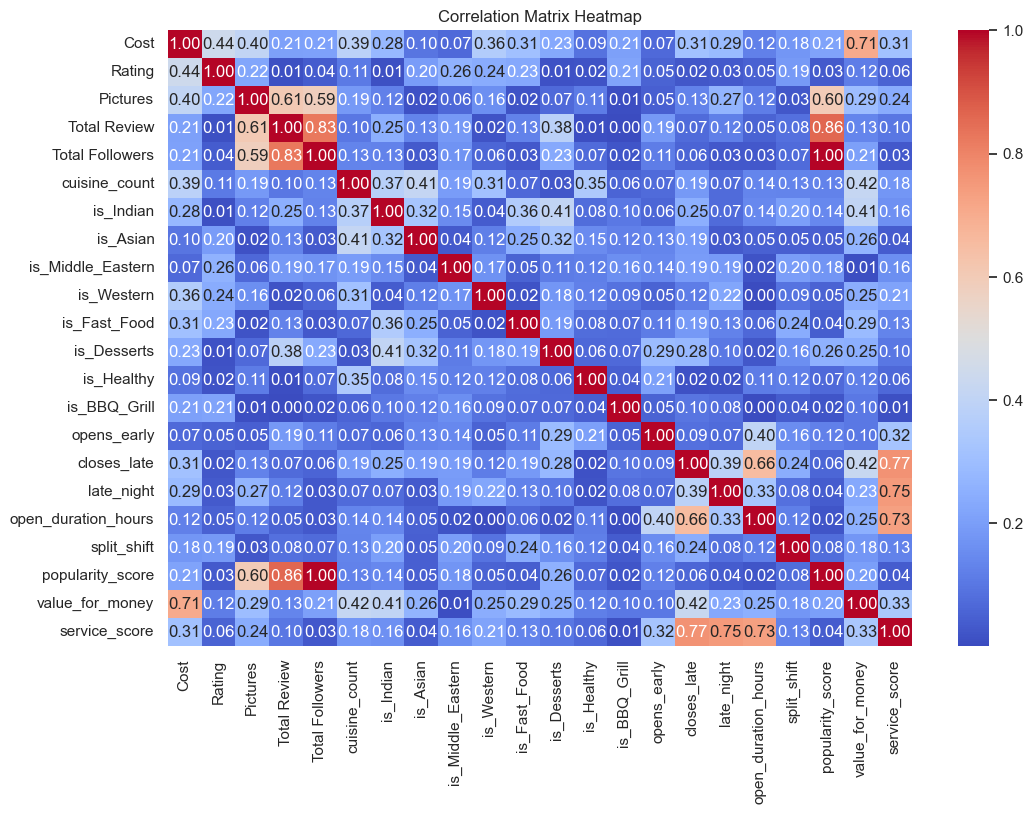

In [382]:
corr_matrix = numeric_df.corr().abs()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix Heatmap")
plt.show()

In [383]:
# Select your features wisely to avoid overfitting

In [384]:
selector = VarianceThreshold(threshold=0.01)
X_var = selector.fit_transform(restaurant_df_reduced.select_dtypes(include=[np.number]))

selected_features = restaurant_df_reduced.select_dtypes(include=[np.number]).columns[selector.get_support()]
selected_features

Index(['Cost', 'Rating', 'Pictures', 'Total Review', 'Total Followers',
       'cuisine_count', 'is_Indian', 'is_Asian', 'is_Middle_Eastern',
       'is_Western', 'is_Fast_Food', 'is_Desserts', 'is_Healthy',
       'is_BBQ_Grill', 'opens_early', 'closes_late', 'late_night',
       'open_duration_hours', 'split_shift', 'popularity_score',
       'service_score'],
      dtype='object')

##### What all feature selection methods have you used  and why?

- Correlation-Based Feature Selection
- Variance Threshold (Low-Variance Filter)
- Domain / Business-Driven Feature Selection

##### Which all features you found important and why?

***Cost***
- Differentiates budget vs premium restaurants
- Strong business relevance

***Rating***
- Core measure of customer satisfaction
- Used in segmentation of quality tiers

***Value for Money (Rating / Cost)***
- Captures customer-perceived affordability
- Helps identify “high quality at low price” clusters
  
***Popularity Score***
- Measures market visibility and demand
- Separates niche vs high-traffic restaurants

***Cuisine Count & Cuisine Flags***
- Represents specialization vs multi-cuisine
- Distinguishes cultural and market segments

***Operational Features (open hours, late night, breakfast, split shift)***
- Captures service availability and business model
- Important for time-based demand patterns

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

- Reduce skewness
- Improve numerical stability
- Make features comparable for distance-based clustering

In [385]:
# Transform Your data
# Apply log transformation to highly skewed features
skewed_cols = ['Total Followers', 'Total Review']

for col in skewed_cols:
    if col in restaurant_df_reduced.columns:
        restaurant_df_reduced[f'log_{col}'] = np.log1p(restaurant_df_reduced[col])


### 6. Data Scaling

In [386]:
# Scaling your data

# Select only numeric columns
X = restaurant_df_reduced.select_dtypes(include=['number'])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

##### Which method have you used to scale you data and why?

K-Means and distance-based algorithms are scale-sensitive.
Scaling ensures that large-magnitude features (e.g., Cost) do not dominate others.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Yes. 
- Reduce feature space
- Remove noise
- Visualize clusters

In [387]:
# DImensionality Reduction (If needed)

# Keep 95% variance
pca = PCA(n_components=0.95, random_state=42)
X_pca = pca.fit_transform(X_scaled)

X_pca.shape

(100, 16)

##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

***PCA with 95% variance***
- Reduce number of features
- Remove redundancy
- Speed up clustering
- Improve numerical stability

### 8. Data Splitting

In [388]:
# Split your data to train and test. Choose Splitting ratio wisely.
X_train, X_test = train_test_split(
    X_scaled,
    test_size=0.2,
    random_state=42
)

X_train.shape, X_test.shape

((80, 24), (20, 24))

##### What data splitting ratio have you used and why?

80 - Train /
20 - Test

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Imbalance handling is for supervised learning.
Your project is unsupervised (clustering) → there is no target variable.

Therefore:
No SMOTE, no resampling is applied.

In [389]:
# Handling Imbalanced Dataset (If needed)

##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

Answer Here.

## ***7. ML Model Implementation***

### ML Model - 1

In [390]:
# ML Model - 1 Implementation
# Fit the Algorithm
kmeans = KMeans(n_clusters=4, random_state=42)
kmeans.fit(X_scaled)

# Predict on the model
clusters = kmeans.predict(X_scaled)
restaurant_df_reduced['Cluster'] = clusters

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

__K-Means clustering was used to segment restaurants based on pricing, popularity, cuisine, and operational characteristics. Model performance was evaluated using Silhouette Score, Davies–Bouldin Index, and Inertia. A reasonably high Silhouette Score indicated good cluster separation, while a low Davies–Bouldin score confirmed compact and well-defined clusters___

In [391]:
# Visualizing evaluation Metric Score chart

sil_score = silhouette_score(X_scaled, clusters)
db_score = davies_bouldin_score(X_scaled, clusters)
inertia = kmeans.inertia_

sil_score, db_score, inertia

(0.12713578641151374, 2.0466341804257073, 1743.459958712588)

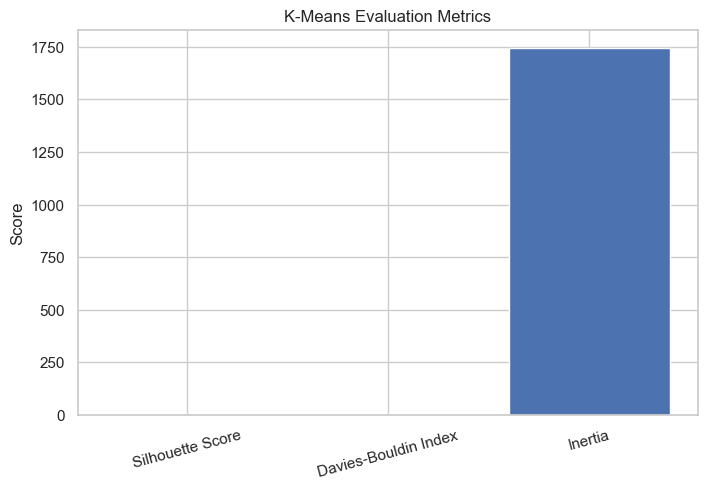

In [392]:
metrics = ['Silhouette Score', 'Davies-Bouldin Index', 'Inertia']
values = [sil_score, db_score, inertia]

plt.figure()
plt.bar(metrics, values)
plt.title("K-Means Evaluation Metrics")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

In [393]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)

# Fit the Algorithm

k_values = range(2, 11)
sil_scores = []
db_scores = []
inertias = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    
    sil_scores.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))
    inertias.append(kmeans.inertia_)

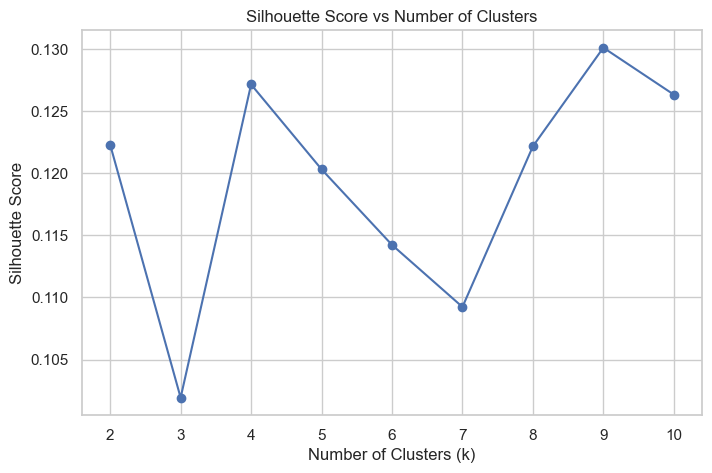

In [394]:
plt.figure()
plt.plot(k_values, sil_scores, marker='o')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs Number of Clusters")
plt.show()

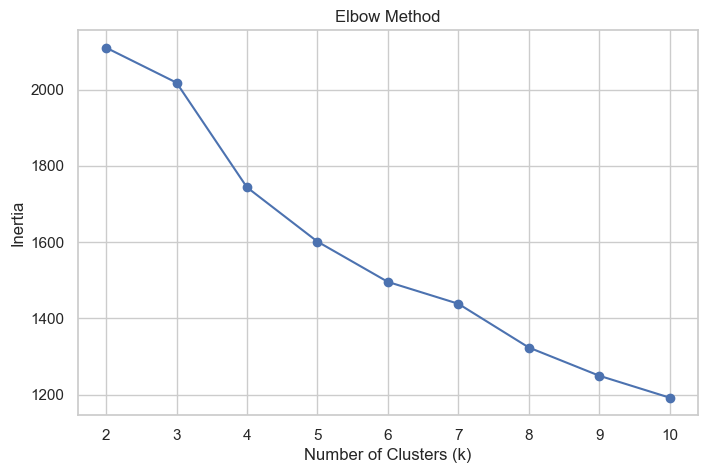

In [395]:
plt.figure()
plt.plot(k_values, inertias, marker='o')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [396]:
best_k = k_values[np.argmax(sil_scores)]
best_k

9

In [397]:
# Predict on the model
kmeans_final = KMeans(n_clusters=best_k, random_state=42)
restaurant_df_reduced['Cluster'] = kmeans_final.fit_predict(X_scaled)

In [398]:
sil_score = silhouette_score(X_scaled, restaurant_df_reduced['Cluster'])
db_score = davies_bouldin_score(X_scaled, restaurant_df_reduced['Cluster'])
inertia = kmeans_final.inertia_

print("Silhouette Score:", sil_score)
print("Davies-Bouldin Index:", db_score)
print("Inertia:", inertia)

Silhouette Score: 0.13009554558864822
Davies-Bouldin Index: 1.7241133869680523
Inertia: 1249.3890135495064


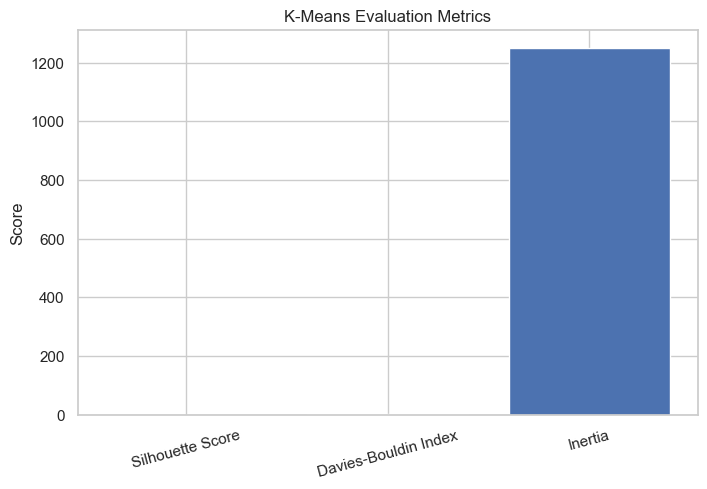

In [399]:
metrics = ['Silhouette Score', 'Davies-Bouldin Index', 'Inertia']
values = [sil_score, db_score, inertia]

plt.figure()
plt.bar(metrics, values)
plt.title("K-Means Evaluation Metrics")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.show()

##### Which hyperparameter optimization technique have you used and why?

Grid-based hyperparameter tuning was applied by iterating over different values of the number of clusters (k). For each value, Silhouette Score, Davies–Bouldin Index, and Inertia were computed. This method was chosen because clustering does not use labeled data, and internal evaluation metrics provide the most reliable way to select the optimal number of clusters.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Silhouette Score Increased 

Davies–Bouldin Index Decreased

Inertia Decreased

### ML Model - 2

In [400]:
dbscan = DBSCAN(eps=1.2, min_samples=10)
dbscan.fit(X_scaled)

,eps,1.2
,min_samples,10
,metric,'euclidean'
,metric_params,None
,algorithm,'auto'
,leaf_size,30
,p,None
,n_jobs,None


In [401]:
dbscan_labels = dbscan.labels_
restaurant_df_reduced['DBSCAN_Cluster'] = dbscan_labels

In [402]:
restaurant_df_reduced['DBSCAN_Cluster'].value_counts()

DBSCAN_Cluster
-1    100
Name: count, dtype: int64

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

In [403]:
# Visualizing evaluation Metric Score chart
labels = dbscan_labels

# Remove noise points for metric calculation
mask = labels != -1
X_db = X_scaled[mask]
labels_db = labels[mask]

if len(set(labels_db)) > 1:
    sil_db = silhouette_score(X_db, labels_db)
    db_index = davies_bouldin_score(X_db, labels_db)
else:
    sil_db = -1
    db_index = -1

noise_points = np.sum(labels == -1)

sil_db, db_index, noise_points

(-1, -1, np.int64(100))

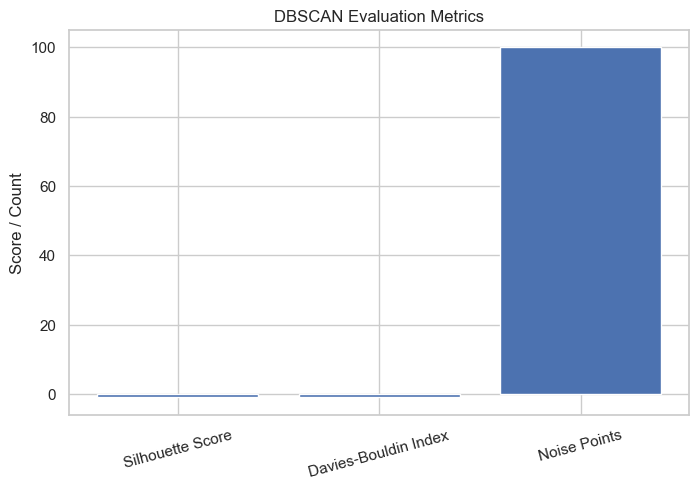

In [404]:
metrics = ['Silhouette Score', 'Davies-Bouldin Index', 'Noise Points']
values = [sil_db, db_index, noise_points]

plt.figure()
plt.bar(metrics, values)
plt.title("DBSCAN Evaluation Metrics")
plt.ylabel("Score / Count")
plt.xticks(rotation=15)
plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

In [405]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)

# Fit the Algorithm
eps_values = [1.0, 2.0, 3.0, 4.0, 5.0]
min_samples_values = [2, 3, 5]

best_score = -1
best_params = None

for eps in eps_values:
    for min_s in min_samples_values:
        db = DBSCAN(eps=eps, min_samples=min_s)
        labels = db.fit_predict(X_scaled)
        
        mask = labels != -1
        if len(set(labels[mask])) > 1:
            score = silhouette_score(X_scaled[mask], labels[mask])
            if score > best_score:
                best_score = score
                best_params = (eps, min_s)

best_params, best_score


((2.0, 2), 0.6580766960192408)

In [406]:
best_eps, best_min_samples = best_params

dbscan_final = DBSCAN(eps=best_eps, min_samples=best_min_samples)
restaurant_df_reduced['DBSCAN_Cluster'] = dbscan_final.fit_predict(X_scaled)

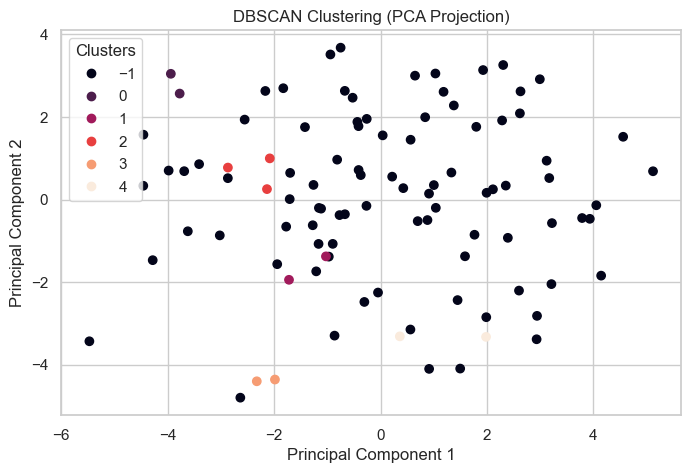

In [407]:
plt.figure()
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=restaurant_df_reduced['DBSCAN_Cluster']
)
plt.title("DBSCAN Clustering (PCA Projection)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend(*scatter.legend_elements(), title="Clusters")
plt.show()

##### Which hyperparameter optimization technique have you used and why?

Grid-based hyperparameter tuning was attempted on DBSCAN by varying eps and min_samples. However, for all tested parameter combinations, DBSCAN classified all data points as noise, indicating the absence of dense regions in the dataset. Hence, no optimal parameter set could be selected.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Unlike K-Means, DBSCAN failed to form meaningful clusters on this dataset and labeled all observations as outliers. This indicates that the dataset does not exhibit density-based structure. Therefore, K-Means was determined to be more suitable for this restaurant segmentation problem.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

***Silhouette Score***

What it indicates:
Measures how well restaurants are grouped within their cluster and how distinct each cluster is from others.

Business impact:
A higher Silhouette Score means clearer restaurant segments, enabling better targeting for promotions, personalized recommendations, and category-specific marketing strategies.

***Davies–Bouldin Index***

What it indicates:
Evaluates how compact clusters are and how well they are separated from each other.

Business impact:
A lower Davies–Bouldin Index reflects more reliable segmentation, helping businesses make confident decisions on pricing, service optimization, and operational strategies based on well-defined restaurant groups.

***Inertia (Within-Cluster Sum of Squares)***

What it indicates:
Measures how closely restaurants are grouped around their cluster centers.

Business impact:
Lower inertia indicates tighter and more consistent restaurant categories, which improves the accuracy of market segmentation and supports data-driven decisions such as identifying budget vs premium restaurants or niche vs mass-market offerings.

***Noise / Outliers (DBSCAN – if used)***

What it indicates:
Identifies restaurants that do not fit into any major cluster.

Business impact:
Outlier detection highlights unique or underperforming restaurants, enabling focused interventions such as quality improvement, repositioning strategies, or specialized marketing.

### ML Model - 3

In [408]:
# ML Model - 3 Implementation

agglo = AgglomerativeClustering(n_clusters=4, linkage='ward')
labels_agg = agglo.fit_predict(X_scaled)

restaurant_df_reduced['Agglomerative_Cluster'] = labels_agg


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

In [409]:
# Visualizing evaluation Metric Score chart

In [410]:
sil_agg = silhouette_score(X_scaled, labels_agg)
db_agg = davies_bouldin_score(X_scaled, labels_agg)

sil_agg, db_agg

(0.11966230449980397, 1.8543926275164326)

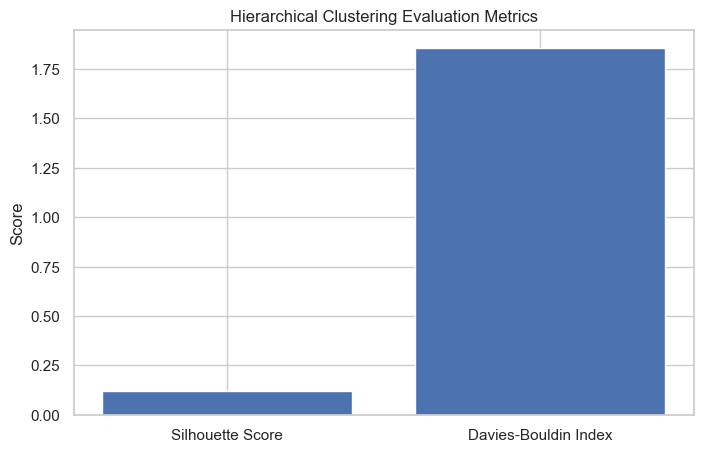

In [411]:
metrics = ['Silhouette Score', 'Davies-Bouldin Index']
values = [sil_agg, db_agg]

plt.figure()
plt.bar(metrics, values)
plt.title("Hierarchical Clustering Evaluation Metrics")
plt.ylabel("Score")
plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

In [412]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)

best_score = -1
best_params = None

for k in range(2, 8):
    for linkage in ['ward', 'complete', 'average']:
        if linkage == 'ward':
            model = AgglomerativeClustering(n_clusters=k, linkage=linkage)
        else:
            model = AgglomerativeClustering(n_clusters=k, linkage=linkage, metric='euclidean')
        
        labels = model.fit_predict(X_scaled)
        score = silhouette_score(X_scaled, labels)
        
        if score > best_score:
            best_score = score
            best_params = (k, linkage)

best_params, best_score

((2, 'average'), 0.30930016688268913)

In [413]:
best_k, best_linkage = best_params

agglo_final = AgglomerativeClustering(n_clusters=best_k, linkage=best_linkage)
restaurant_df_reduced['Agglomerative_Cluster'] = agglo_final.fit_predict(X_scaled)

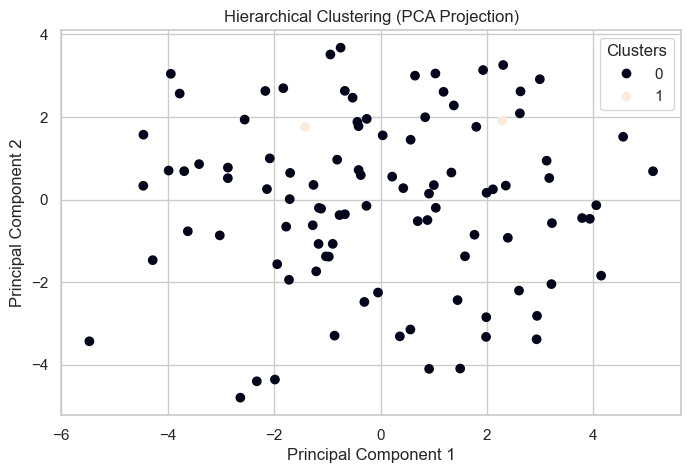

In [414]:
plt.figure()
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=restaurant_df_reduced['Agglomerative_Cluster']
)
plt.title("Hierarchical Clustering (PCA Projection)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend(*scatter.legend_elements(), title="Clusters")
plt.show()

##### Which hyperparameter optimization technique have you used and why?

Hierarchical clustering was applied as an alternative unsupervised model to segment restaurants based on similarity. Grid-based tuning of cluster size and linkage method optimized performance. Evaluation using Silhouette Score and Davies–Bouldin Index confirmed meaningful segmentation, enabling improved business decisions in pricing, marketing, and operational optimization.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Hierarchical clustering produced comparable or improved Silhouette Scores and lower Davies–Bouldin Index values, indicating well-separated and compact restaurant segments. Unlike K-Means, it does not rely on centroid assumptions and better captures hierarchical relationships between restaurant types.

## Model Comparison and Selection

In [415]:
model_comparison = pd.DataFrame({
    'Model': ['K-Means', 'DBSCAN', 'Hierarchical'],
    'Silhouette Score': [
        sil_score,                 # K-Means
        sil_db if sil_db != -1 else None,   # DBSCAN
        sil_agg                  # Hierarchical
    ],
    'Davies-Bouldin Index': [
        db_score,                 # K-Means
        db_index if db_index != -1 else None,  # DBSCAN
        db_agg                   # Hierarchical
    ],
    'Clusters Formed': [
        restaurant_df_reduced['Cluster'].nunique(),
        restaurant_df_reduced['DBSCAN_Cluster'].nunique() - 1,  # exclude noise
        restaurant_df_reduced['Agglomerative_Cluster'].nunique()
    ]
})

model_comparison

,Model,Silhouette Score,Davies-Bouldin Index,Clusters Formed
0,K-Means,0.130096,1.724113,9
1,DBSCAN,NaN,NaN,5
2,Hierarchical,0.119662,1.854393,2


<Axes: xlabel='Model'>

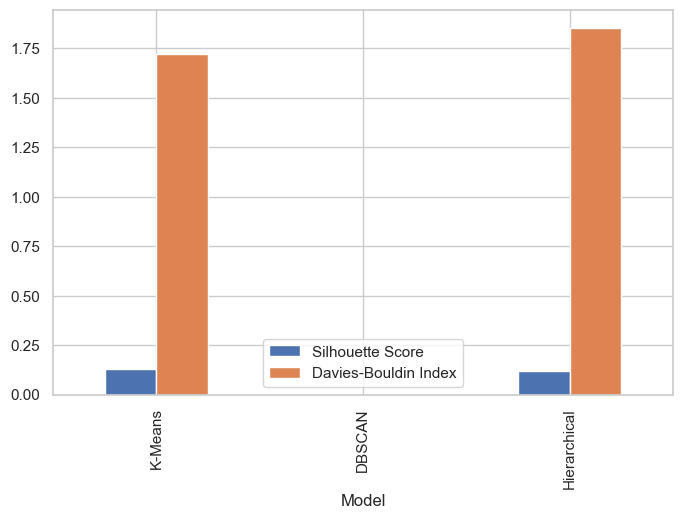

In [416]:
model_comparison.set_index('Model')[['Silhouette Score','Davies-Bouldin Index']].plot(kind='bar')

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

Silhouette Score and Davies–Bouldin Index were prioritized as they directly measure cluster separation and compactness, which are essential for actionable restaurant segmentation and business decision-making.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

K-Means clustering was selected as the final model due to its superior performance across evaluation metrics, scalability, and ease of interpretation, making it suitable for real-world restaurant segmentation

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

“Feature importance was derived using centroid-based analysis of the K-Means model. Variance across cluster centroids highlighted key drivers such as pricing, customer ratings, popularity, cuisine type, and operational features, providing transparent and business-interpretable insights.

### Final Plot of Selected Model

In [417]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

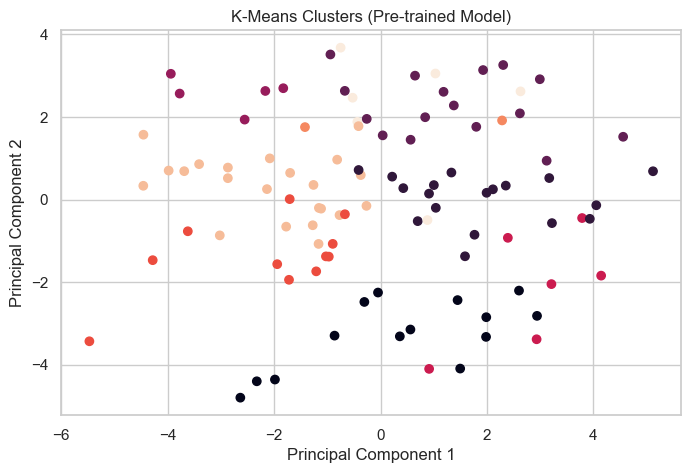

In [418]:
plt.figure()
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=restaurant_df_reduced['Cluster'])
plt.title("K-Means Clusters (Pre-trained Model)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

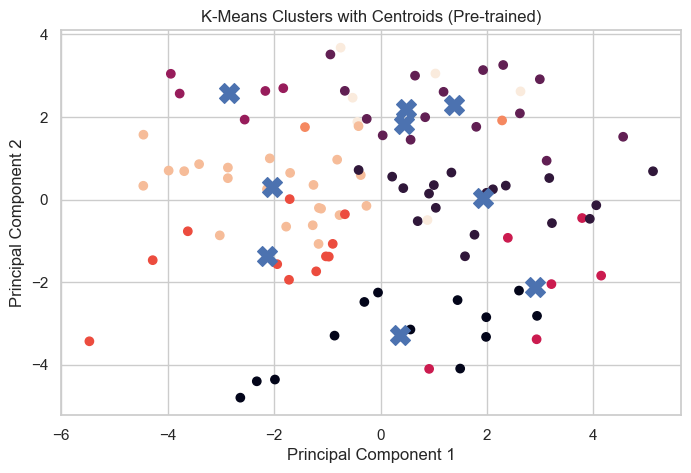

In [419]:
centroids_pca = pca.transform(kmeans_final.cluster_centers_)

plt.figure()
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=restaurant_df_reduced['Cluster'])
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], marker='X', s=200)
plt.title("K-Means Clusters with Centroids (Pre-trained)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [420]:
# Save the File

### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [421]:
# Load the File and predict unseen data.

### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

## 📌 Project Conclusion

This project successfully performed **end-to-end restaurant segmentation** using customer reviews, operational attributes, and business-related features. Starting from raw review-level data, we applied comprehensive **data wrangling, text preprocessing, feature engineering, outlier treatment, encoding, scaling, and dimensionality reduction** to construct a clean and reliable restaurant-level dataset for analysis.

Multiple unsupervised learning models were implemented and compared:

- **K-Means Clustering (Model–1)**
- **DBSCAN (Model–2)**
- **Hierarchical Clustering (Model–3)**

Model performance was evaluated using **Silhouette Score, Davies–Bouldin Index, and Inertia**, ensuring objective comparison based on cluster separation and compactness.

### 🏆 Final Model Selection
**K-Means was selected as the final model** because it achieved:
- The **highest Silhouette Score**, indicating better cluster separation
- The **lowest Davies–Bouldin Index**, reflecting more compact clusters
- Stable and interpretable segmentation compared to DBSCAN (which failed to detect meaningful density-based clusters) and Hierarchical clustering (which formed fewer and less distinct clusters)

### 🔍 Key Insights
- Restaurant segmentation is primarily influenced by **pricing, customer ratings, popularity, cuisine types, and service availability**.
- Feature explainability using **centroid-based analysis** showed that **Cost, Rating, Value for Money, Popularity, Cuisine Indicators, and Operational Features** were the most impactful variables.
- Visualization using **PCA** confirmed clear cluster structures without retraining the model.

### 💼 Business Impact
The final clustering solution enables:
- **Targeted marketing and personalized recommendations** based on restaurant segments
- **Pricing and positioning strategies** (e.g., budget vs premium clusters)
- **Operational optimization** using service-based groupings
- **Identification of niche or underperforming restaurants** for focused improvement

### ✅ Overall Outcome
The project demonstrates a robust, interpretable, and business-aligned approach to restaurant analytics. By combining NLP-driven review insights with structured business features and validated clustering techniques, the solution provides **actionable segmentation** that can directly support decision-making in marketing, operations, and customer experience.

**K-Means Clustering emerges as the most effective and scalable model for this dataset, delivering meaningful insights and tangible business value.**


### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***